# Group C: Scatter plots broken out by Grade Level

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import os

# --- Paths ---
elpac_dir = "../1095 Data/ELPAC/"
enrollment_dir = "../1095 Data/Enrollment"
group_csv = "group_c_ssids.csv"

# --- Load Group A SSIDs ---
group_c_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"Group C: {len(group_a_ssids):,} students")

# --- Load Enrollment files and combine ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")
enrollment_a = enrollment_all[enrollment_all["SSID"].isin(group_c_ssids)]
print(f"Group C enrollment records: {len(enrollment_a):,}")

# --- Load Initial ELPAC files ---
initial_files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
}

initial_dfs = {}
for label, filename in initial_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    initial_dfs[label] = df

# --- Load Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df

# --- Find earliest initial test date per student ---
first_initial_date = {}
for label, df in initial_dfs.items():
    df_group = df[df["SSID"].isin(group_c_ssids)][["SSID", "TestStartDate"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in first_initial_date or row["TestStartDate"] < first_initial_date[ssid]:
            first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with an initial test date: {len(first_initial_date):,}")

# --- Build summative year counts to identify students with all 3 summative scores ---
summative_year_count = {}
for year_num, df in summative_dfs.items():
    for ssid in df["SSID"].dropna().unique():
        summative_year_count[ssid] = summative_year_count.get(ssid, 0) + 1

complete_ssids = {
    ssid for ssid in group_c_ssids
    if summative_year_count.get(ssid, 0) == 3
}
print(f"Group C students with all 3 summative scores: {len(complete_ssids):,}")

# --- Build full scatter dataset (x = days since first initial, y = OverallScaleScore) ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(complete_ssids)].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            records.append({"SSID": ssid, "days": days, "score": row["OverallScaleScore"]})

scatter_df = pd.DataFrame(records)

# --- Apply filters: x > 0 and y > 1000 ---
scatter_df = scatter_df[(scatter_df["days"] > 0) & (scatter_df["score"] > 1000)]
print(f"Filtered scatter points (x > 0, y > 1000): {len(scatter_df):,}")

# --- Merge in grade level from enrollment ---
scatter_df = scatter_df.merge(
    enrollment_a[["SSID", "GradeLevelCode"]].dropna(),
    on="SSID", how="left"
)

# --- Global y-axis max ---
y_max = scatter_df["score"].max() * 1.10
print(f"Global max score: {scatter_df['score'].max():.1f}, y-axis ceiling: {y_max:.1f}")

# --- Get sorted unique grade levels ---
grade_levels = sorted(scatter_df["GradeLevelCode"].dropna().unique())
print(f"\nGrade levels found: {grade_levels}")

Group C: 28,055 students
Group C enrollment records: 28,055
Students with an initial test date: 28,055
Group C students with all 3 summative scores: 28,055
Filtered scatter points (x > 0, y > 1000): 91,521
Global max score: 1829.0, y-axis ceiling: 2011.9

Grade levels found: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', 'KN', 'PS']


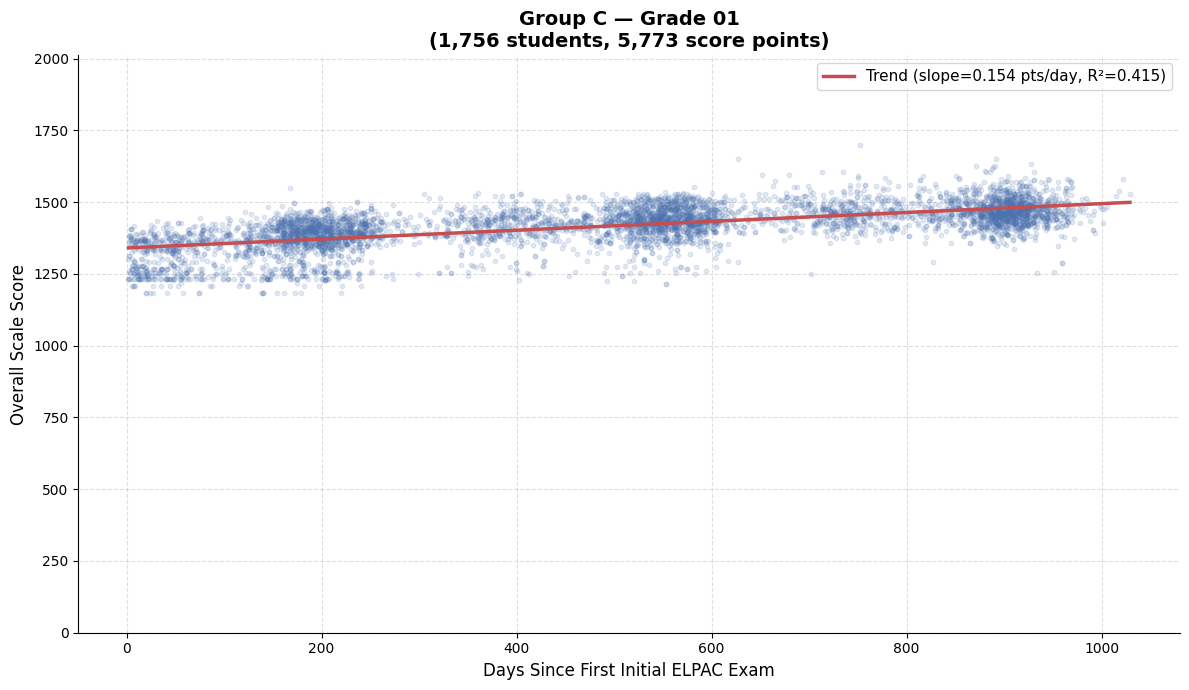

Saved: plots/group_c_grade_01_scatter.png


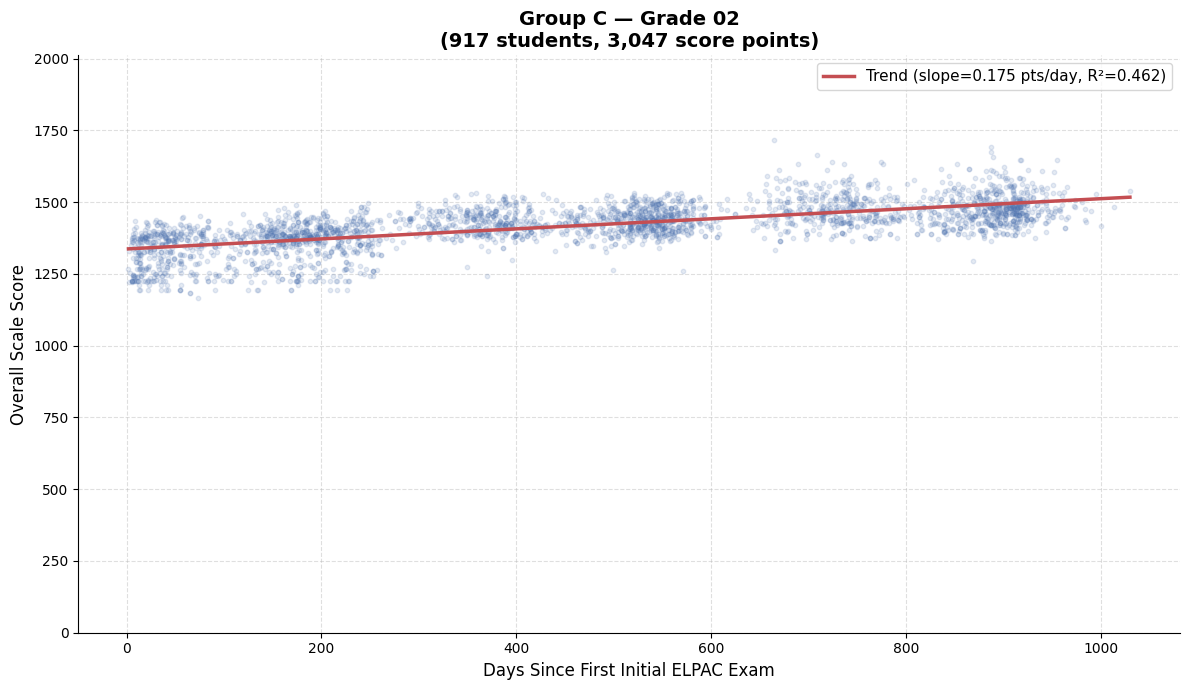

Saved: plots/group_c_grade_02_scatter.png


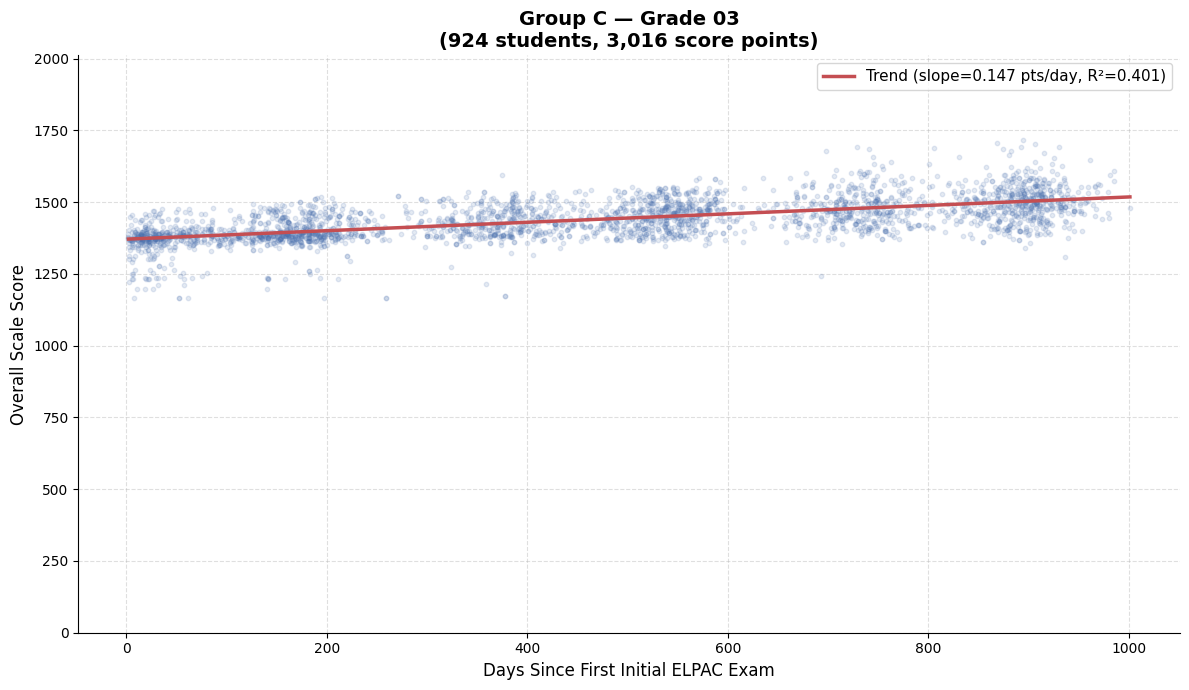

Saved: plots/group_c_grade_03_scatter.png


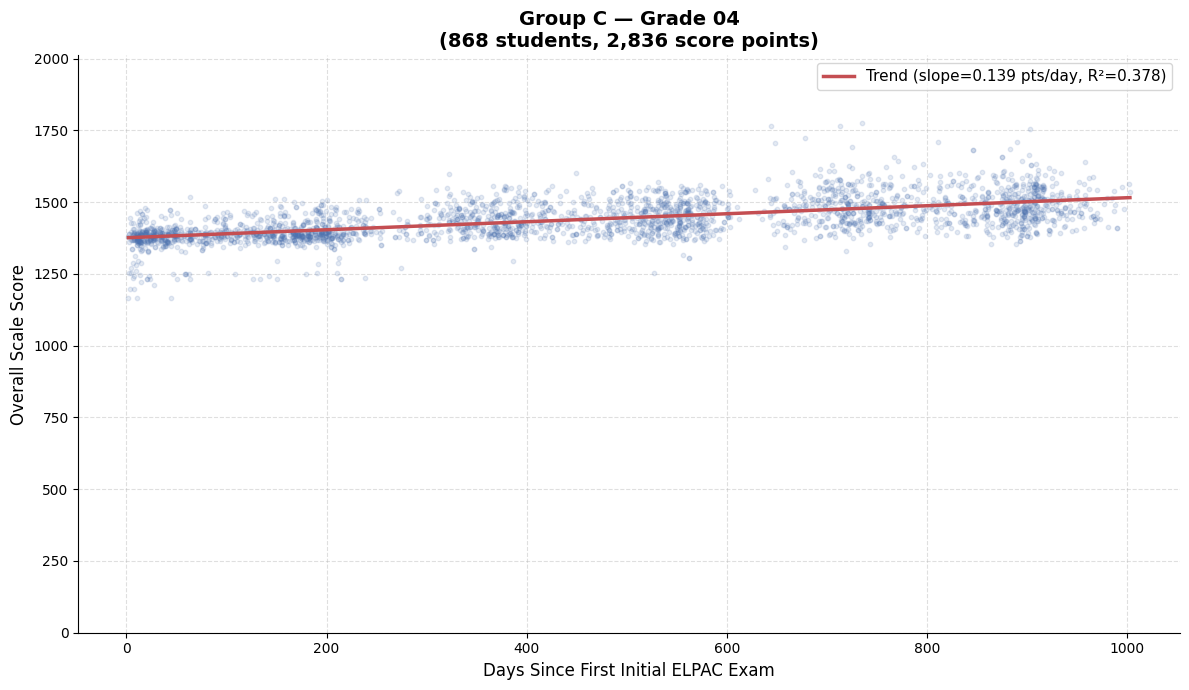

Saved: plots/group_c_grade_04_scatter.png


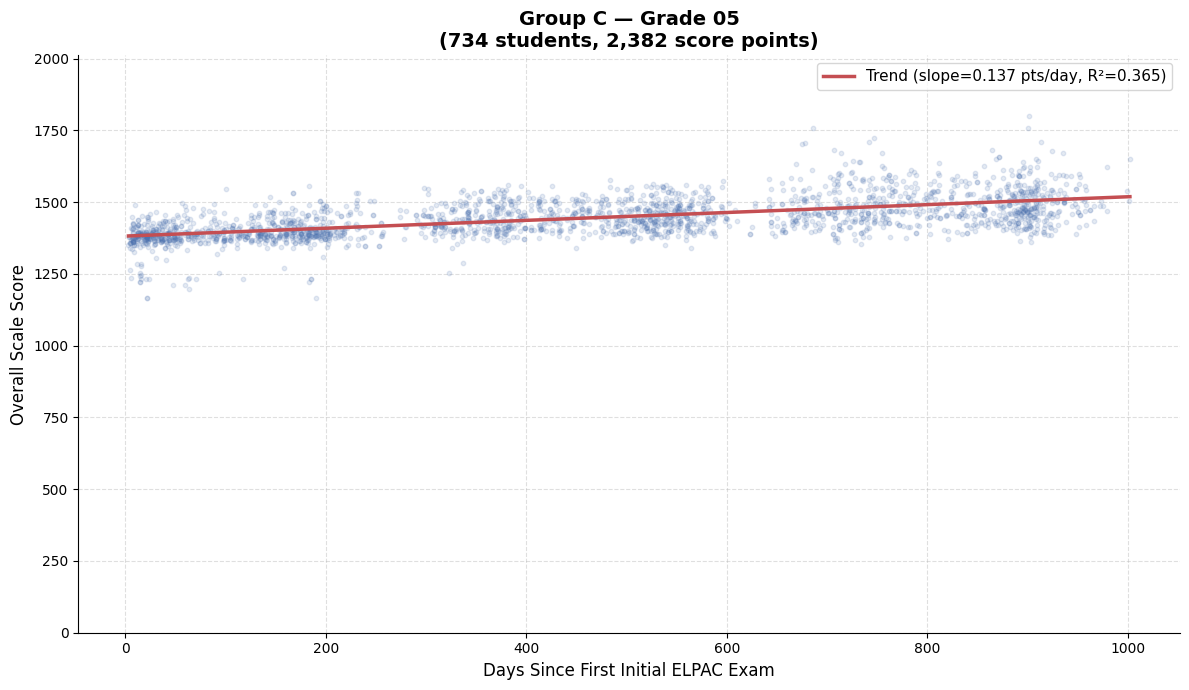

Saved: plots/group_c_grade_05_scatter.png


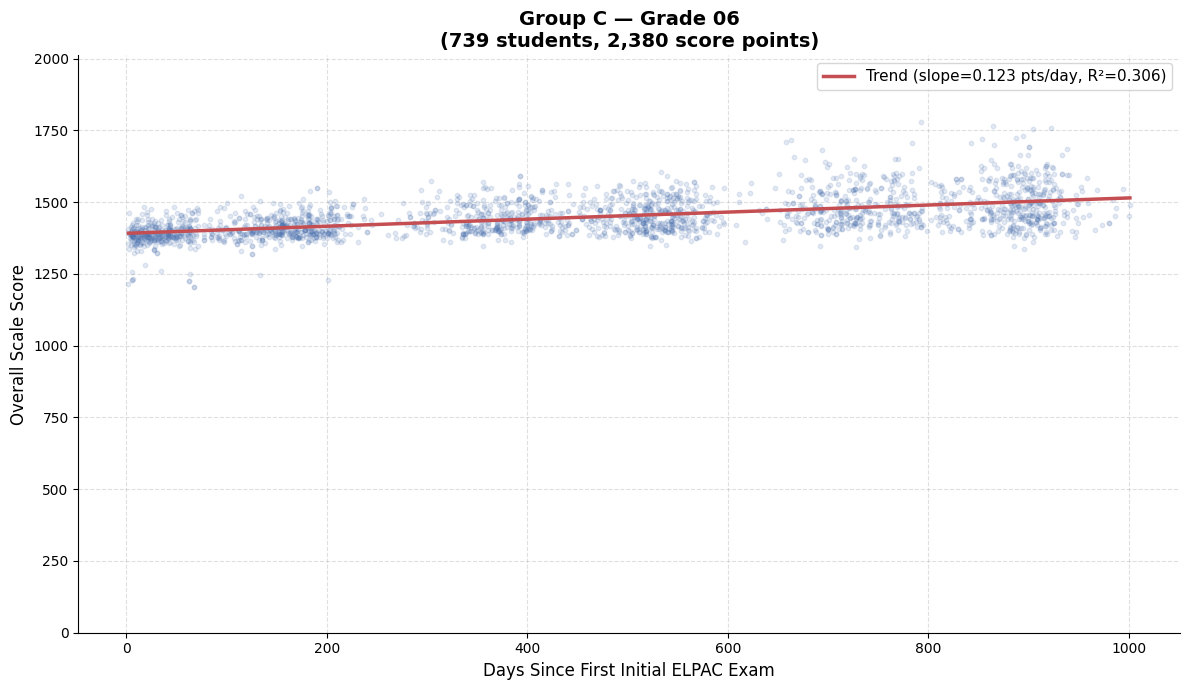

Saved: plots/group_c_grade_06_scatter.png


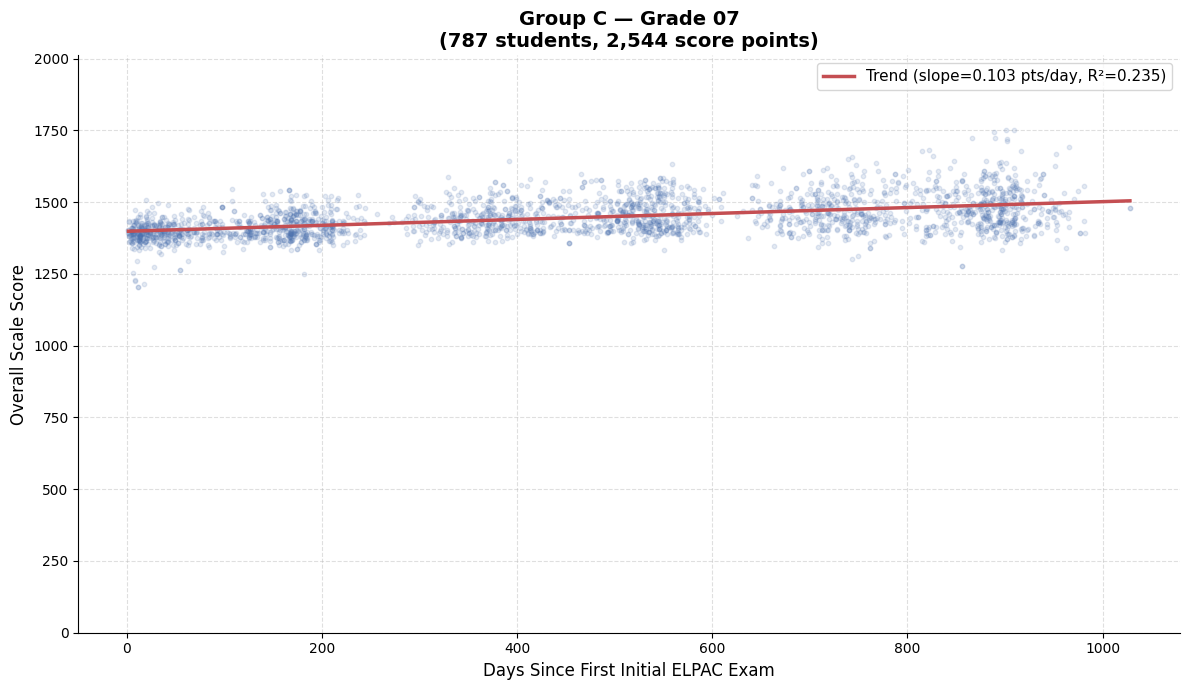

Saved: plots/group_c_grade_07_scatter.png


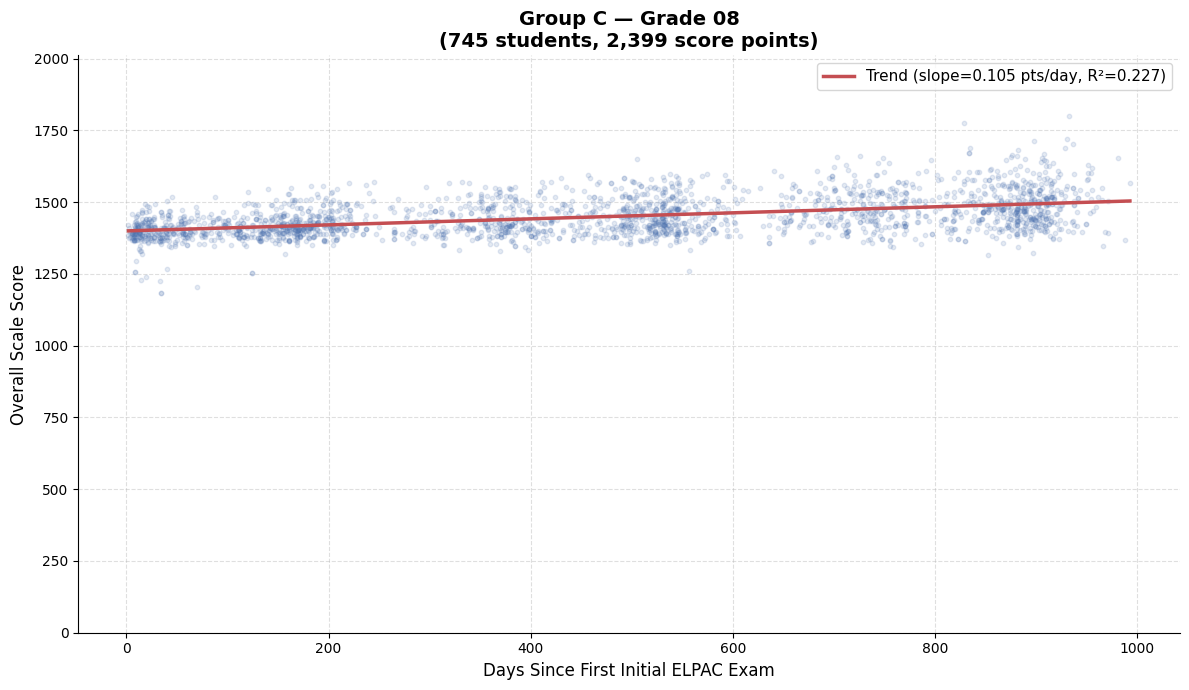

Saved: plots/group_c_grade_08_scatter.png


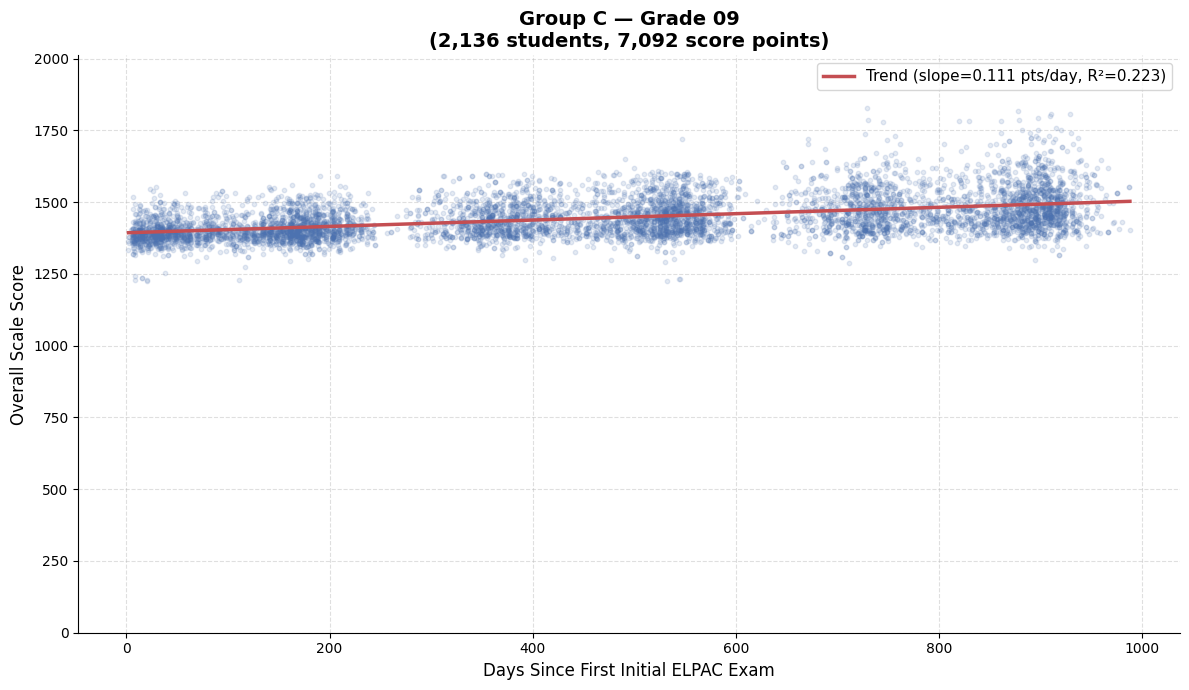

Saved: plots/group_c_grade_09_scatter.png


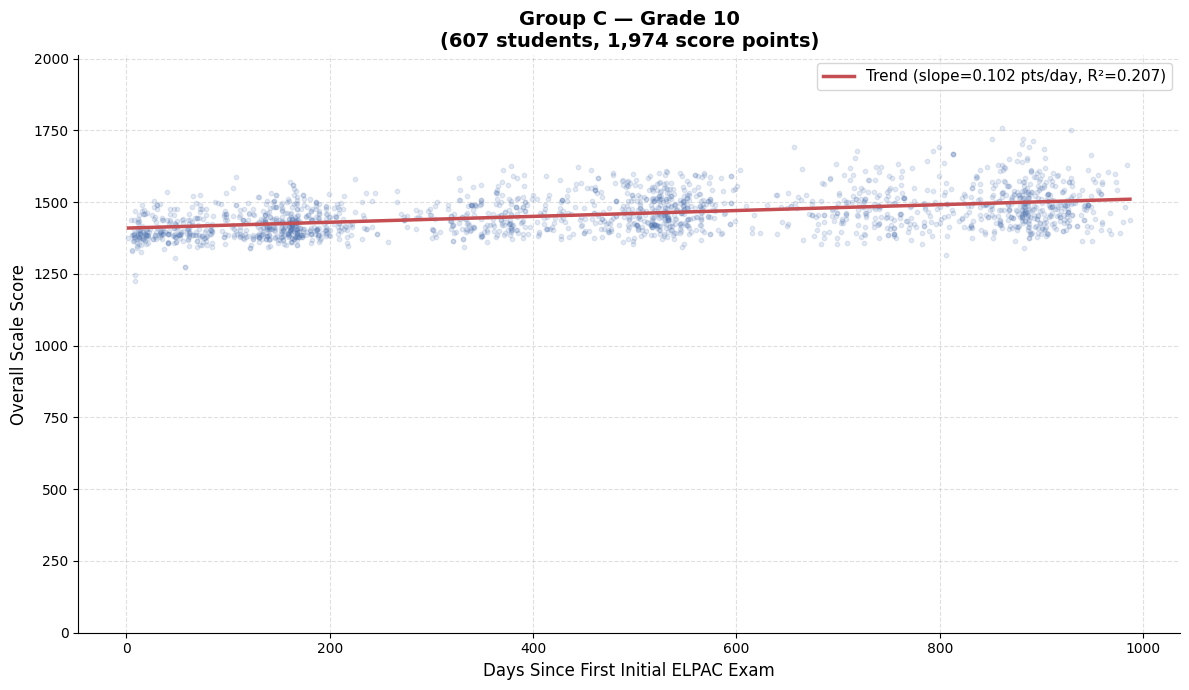

Saved: plots/group_c_grade_10_scatter.png


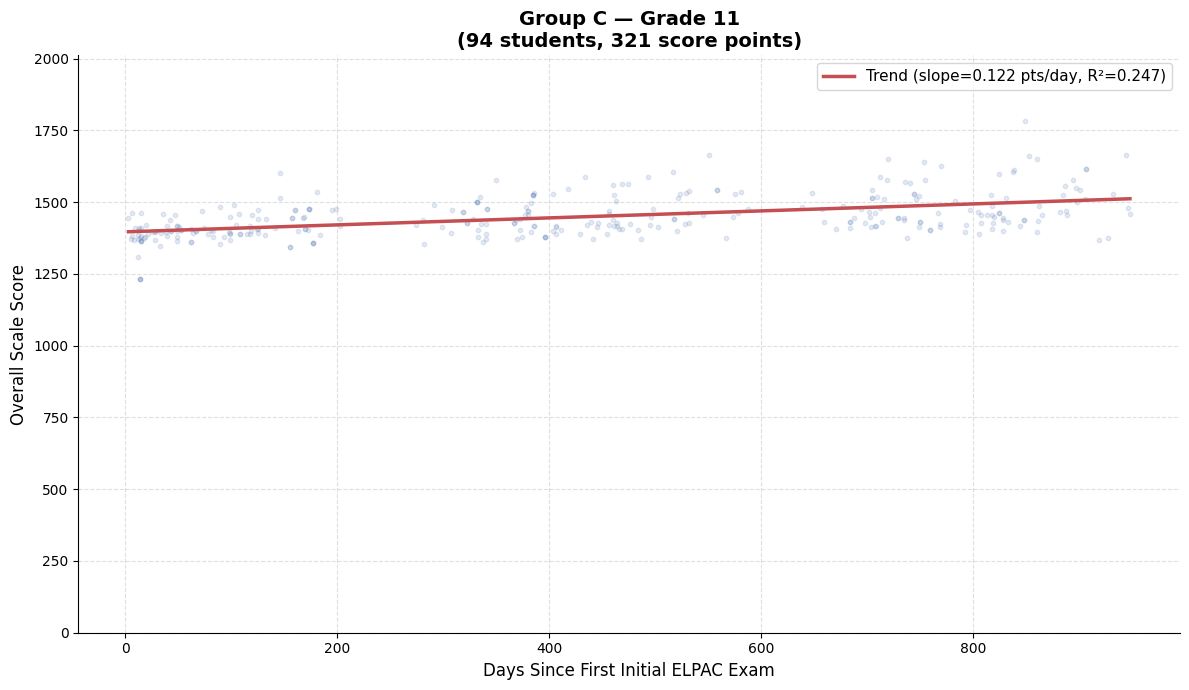

Saved: plots/group_c_grade_11_scatter.png


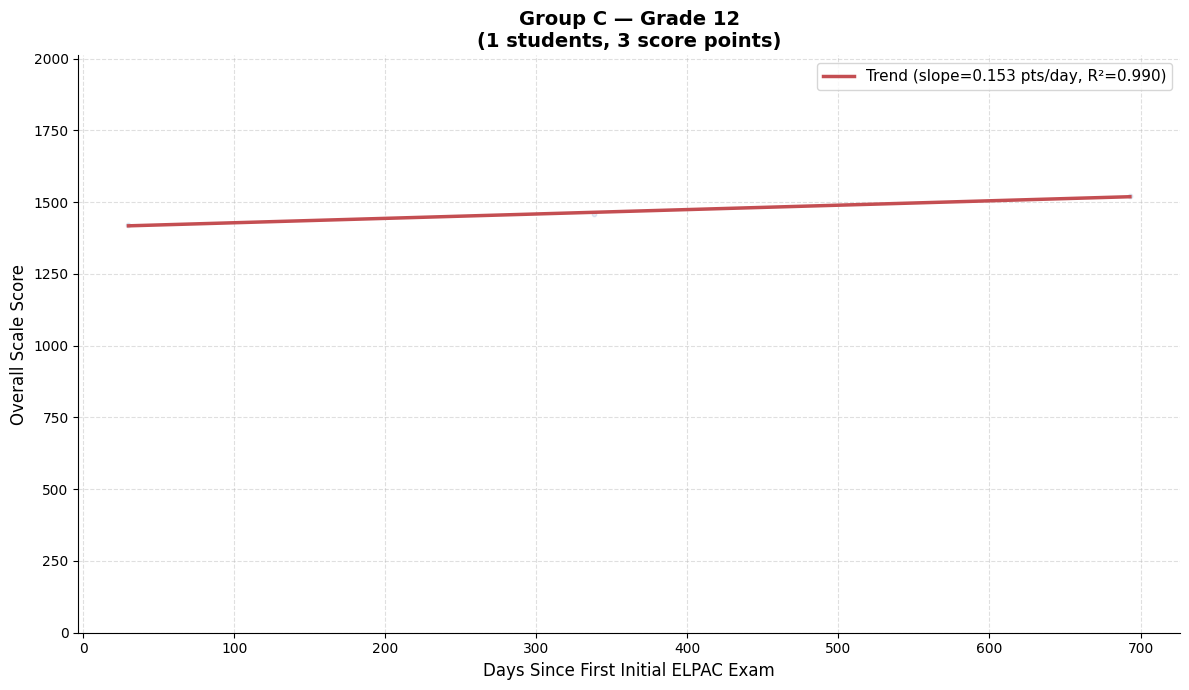

Saved: plots/group_c_grade_12_scatter.png


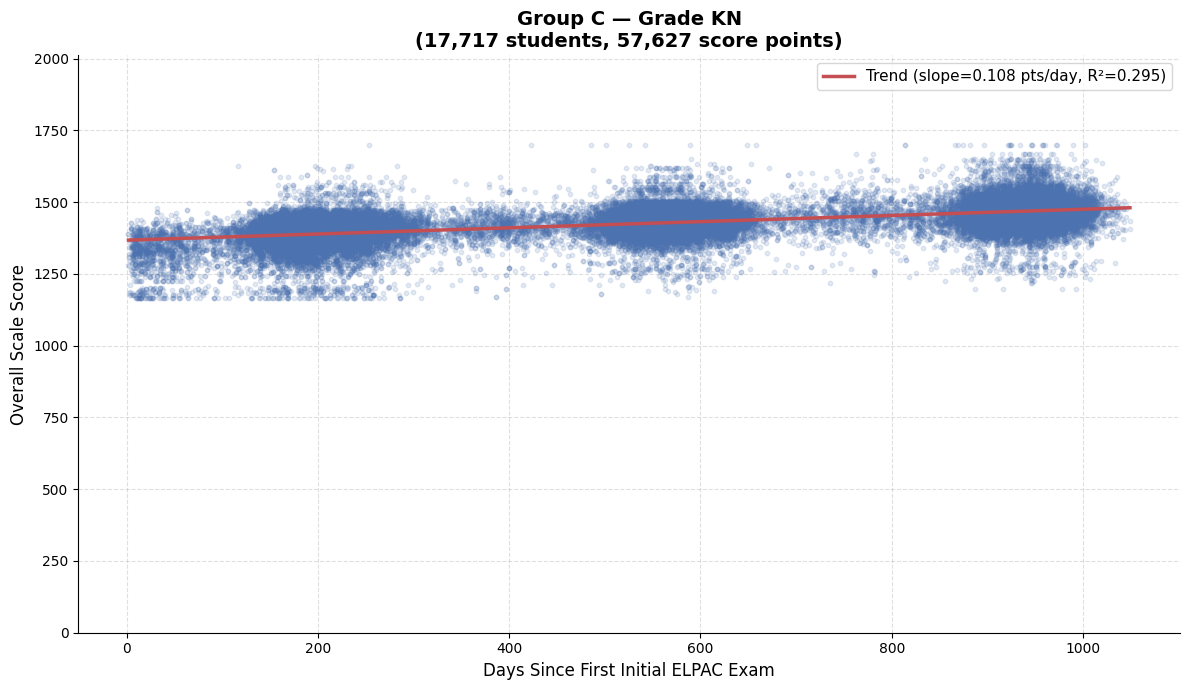

Saved: plots/group_c_grade_KN_scatter.png


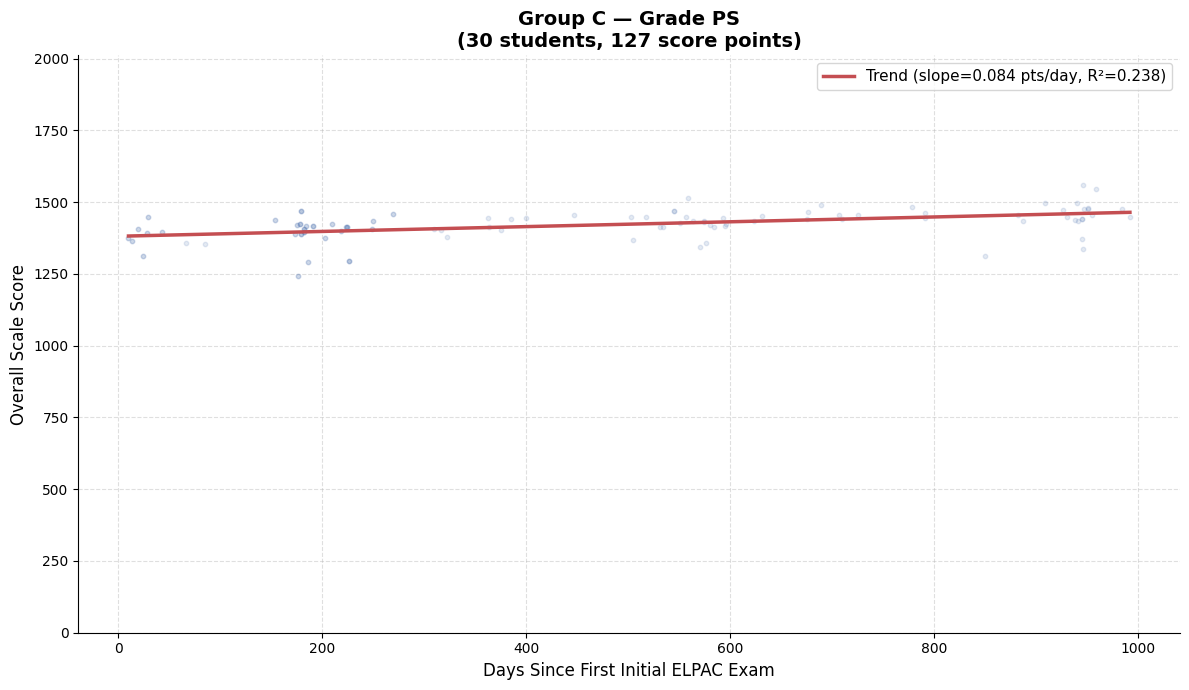

Saved: plots/group_c_grade_PS_scatter.png


In [3]:
# --- One scatter plot per grade level ---
for grade in grade_levels:
    grade_data = scatter_df[scatter_df["GradeLevelCode"] == grade]
    x = grade_data["days"].values
    y = grade_data["score"].values

    if len(x) < 2:
        print(f"Skipping grade {grade} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    # Trend line + R²
    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group C — Grade {grade}\n"
                 f"({grade_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    output_file = f"plots/group_c_grade_{grade}_scatter.png"
    plt.savefig(output_file, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_file}")

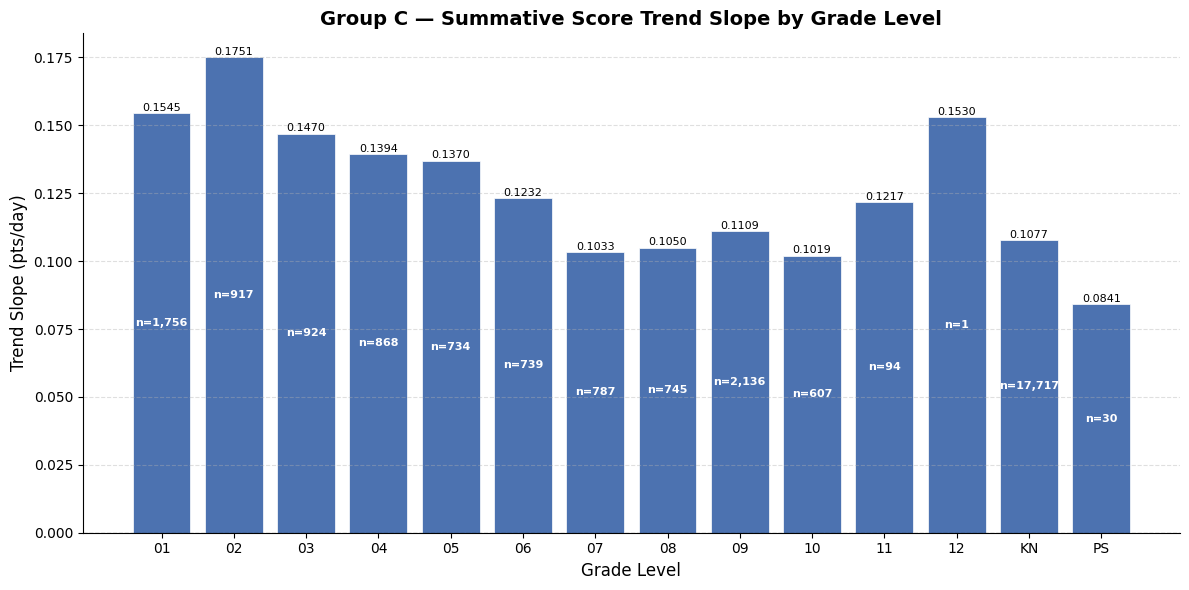

Saved: plots/group_c_slope_by_grade.png


In [4]:
# --- Compute slope and student count per grade level ---
grade_slopes = {}
grade_counts = {}
for grade in grade_levels:
    grade_data = scatter_df[scatter_df["GradeLevelCode"] == grade]
    x = grade_data["days"].values
    y = grade_data["score"].values
    if len(x) < 2:
        continue
    slope, _, _, _, _ = stats.linregress(x, y)
    grade_slopes[grade] = slope
    grade_counts[grade] = grade_data["SSID"].nunique()

grades = list(grade_slopes.keys())
slopes = list(grade_slopes.values())
counts = [grade_counts[g] for g in grades]

# --- Bar chart ---
os.makedirs("plots", exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(grades, slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label on top/bottom of each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center",
        va="bottom" if slope >= 0 else "top",
        fontsize=8
    )

# Student count overlaid in the middle of each bar
for bar, count, slope in zip(bars, counts, slopes):
    bar_mid = bar.get_height() / 2
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar_mid,
        f"n={count:,}",
        ha="center",
        va="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Grade Level", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group C — Summative Score Trend Slope by Grade Level", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_c_slope_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_slope_by_grade.png")

In [5]:
# --- Map grade levels to school groups ---
grade_group_map = {
    "KN": "Elementary", "01": "Elementary", "02": "Elementary",
    "03": "Elementary", "04": "Elementary", "05": "Elementary",
    "06": "Middle School", "07": "Middle School", "08": "Middle School",
    "09": "High School", "10": "High School", "11": "High School", "12": "High School",
}

scatter_df["SchoolGroup"] = scatter_df["GradeLevelCode"].map(grade_group_map)

# Drop PS and any unmapped grades
scatter_df_grouped = scatter_df[scatter_df["SchoolGroup"].notna()].copy()

group_order = ["Elementary", "Middle School", "High School"]
print("Students per school group:")
for group in group_order:
    g = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    print(f"  {group}: {g['SSID'].nunique():,} students, {len(g):,} score points")

Students per school group:
  Elementary: 22,916 students, 74,681 score points
  Middle School: 2,271 students, 7,323 score points
  High School: 2,838 students, 9,390 score points


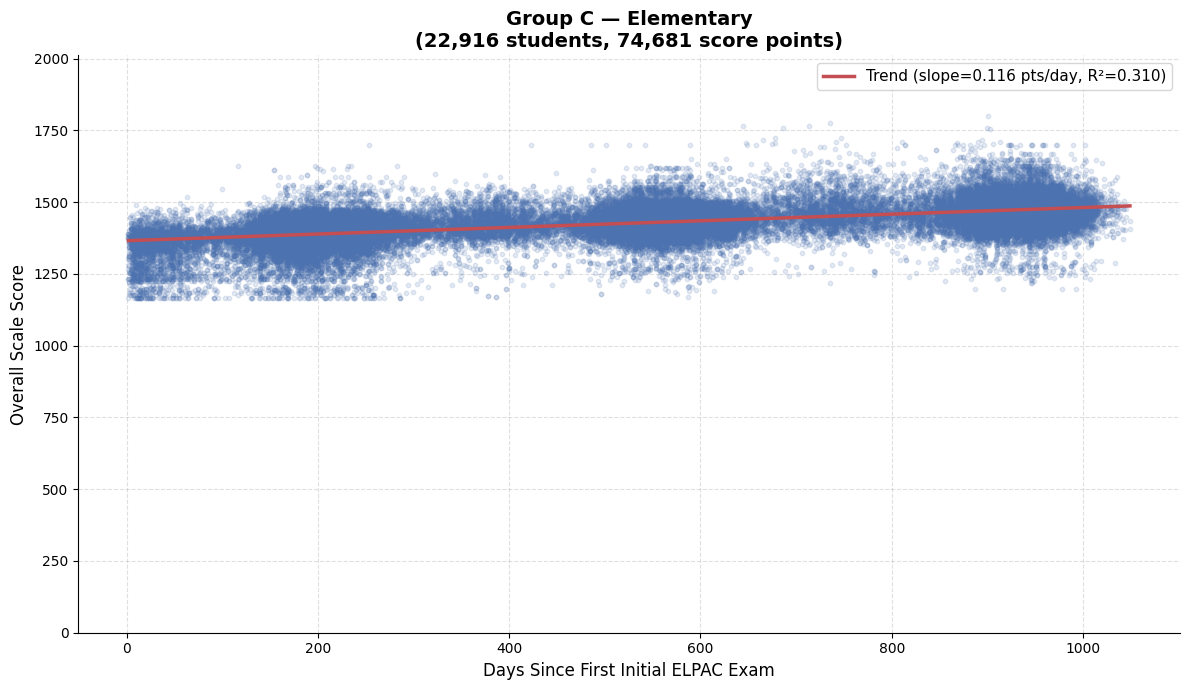

Saved: plots/group_a_elementary_scatter.png


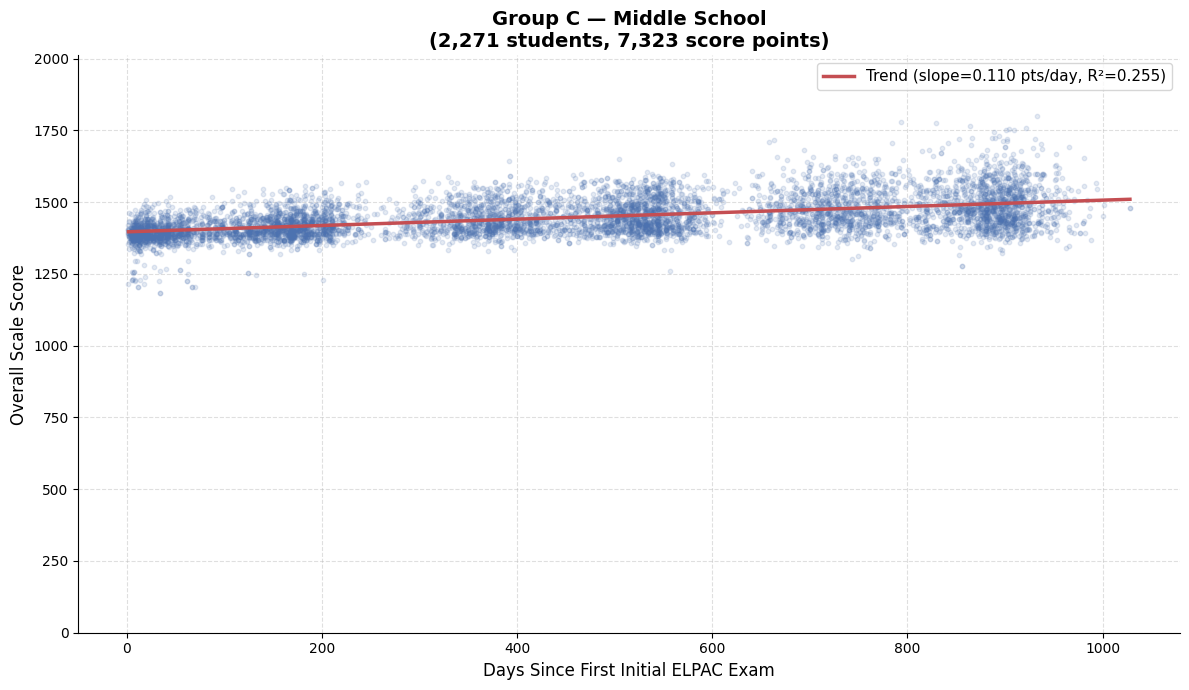

Saved: plots/group_a_middle_school_scatter.png


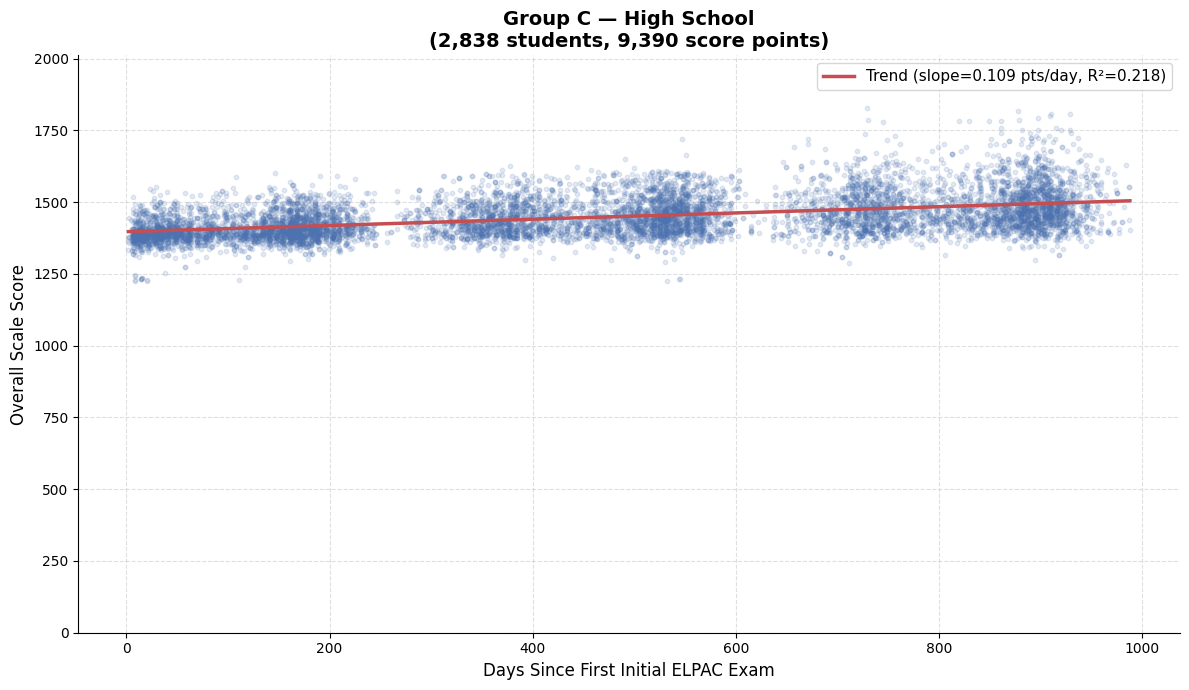

Saved: plots/group_a_high_school_scatter.png


In [6]:
# --- One scatter plot per school group ---
for group in group_order:
    group_data = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    x = group_data["days"].values
    y = group_data["score"].values

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group C — {group}\n"
                 f"({group_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = group.replace(" ", "_").lower()
    plt.savefig(f"plots/group_a_{safe_name}_scatter.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_a_{safe_name}_scatter.png")

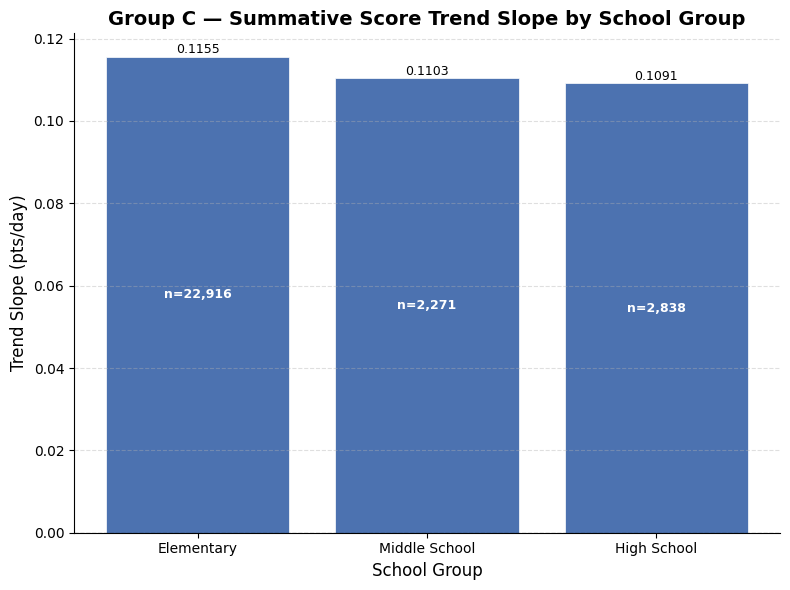

Saved: plots/group_c_slope_by_school_group.png


In [7]:
# --- Slope bar chart by school group ---
group_slopes = {}
group_counts = {}
for group in group_order:
    group_data = scatter_df_grouped[scatter_df_grouped["SchoolGroup"] == group]
    x = group_data["days"].values
    y = group_data["score"].values
    if len(x) < 2:
        continue
    slope, _, _, _, _ = stats.linregress(x, y)
    group_slopes[group] = slope
    group_counts[group] = group_data["SSID"].nunique()

slopes = [group_slopes[g] for g in group_order]
counts = [group_counts[g] for g in group_order]

fig, ax = plt.subplots(figsize=(8, 6))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(group_order, slopes, color=colors, edgecolor="white", linewidth=0.5)

for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=9
    )

for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center", fontsize=9,
        color="white", fontweight="bold"
    )

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("School Group", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group C — Summative Score Trend Slope by School Group", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_c_slope_by_school_group.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_slope_by_school_group.png")

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import os

# --- Paths ---
elpac_dir = "../1095 Data/ELPAC/"
enrollment_dir = "../1095 Data/Enrollment"
group_csv = "group_c_ssids.csv"

os.makedirs("plots", exist_ok=True)

# --- Load Group C SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"Group C: {len(group_ssids):,} students")

# --- Load Enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")
enrollment_c = enrollment_all[enrollment_all["SSID"].isin(group_ssids)]
print(f"Group C enrollment records: {len(enrollment_c):,}")

# --- Load Initial ELPAC files ---
initial_files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
}

initial_dfs = {}
for label, filename in initial_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    initial_dfs[label] = df

# --- Load Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df

# --- Find earliest initial test date per student ---
first_initial_date = {}
for label, df in initial_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)][["SSID", "TestStartDate"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in first_initial_date or row["TestStartDate"] < first_initial_date[ssid]:
            first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with an initial test date: {len(first_initial_date):,}")

# --- Build scatter dataset ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            records.append({
                "SSID": ssid,
                "days": days,
                "score": row["OverallScaleScore"]
            })

scatter_df = pd.DataFrame(records)

# --- Apply filters ---
scatter_df = scatter_df[(scatter_df["days"] > 0) & (scatter_df["score"] > 1000)]
print(f"Filtered scatter points (x > 0, y > 1000): {len(scatter_df):,}")

# --- Merge in district from enrollment ---
scatter_df = scatter_df.merge(
    enrollment_c[["SSID", "CDCode", "Districtname"]].dropna(subset=["CDCode"]),
    on="SSID", how="left"
)

# --- Global y-axis max ---
y_max = scatter_df["score"].max() * 1.10
print(f"Global max score: {scatter_df['score'].max():.1f}, y-axis ceiling: {y_max:.1f}")

# --- Unique districts ---
districts = (
    scatter_df[["CDCode", "Districtname"]]
    .dropna()
    .drop_duplicates()
    .sort_values("Districtname")
)
print(f"Unique districts: {len(districts)}")

Group C: 28,055 students
Group C enrollment records: 28,055
Students with an initial test date: 28,055
Filtered scatter points (x > 0, y > 1000): 91,521
Global max score: 1829.0, y-axis ceiling: 2011.9
Unique districts: 23


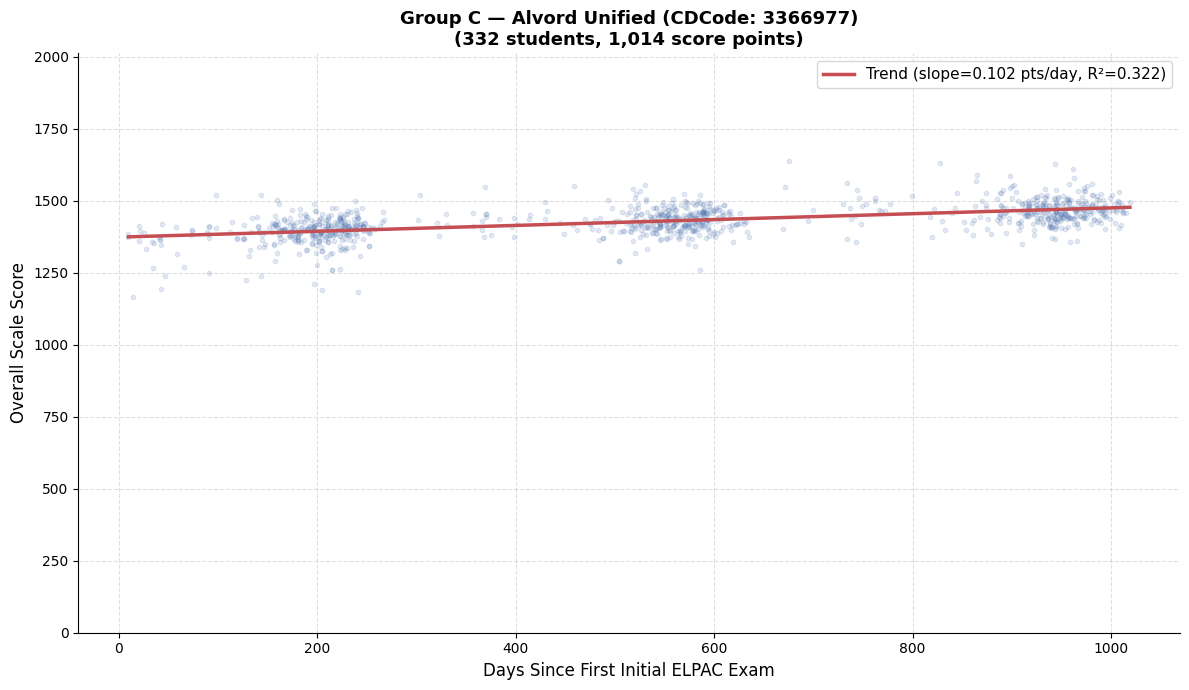

Saved: plots/group_c_district_3366977_Alvord_Unified.png


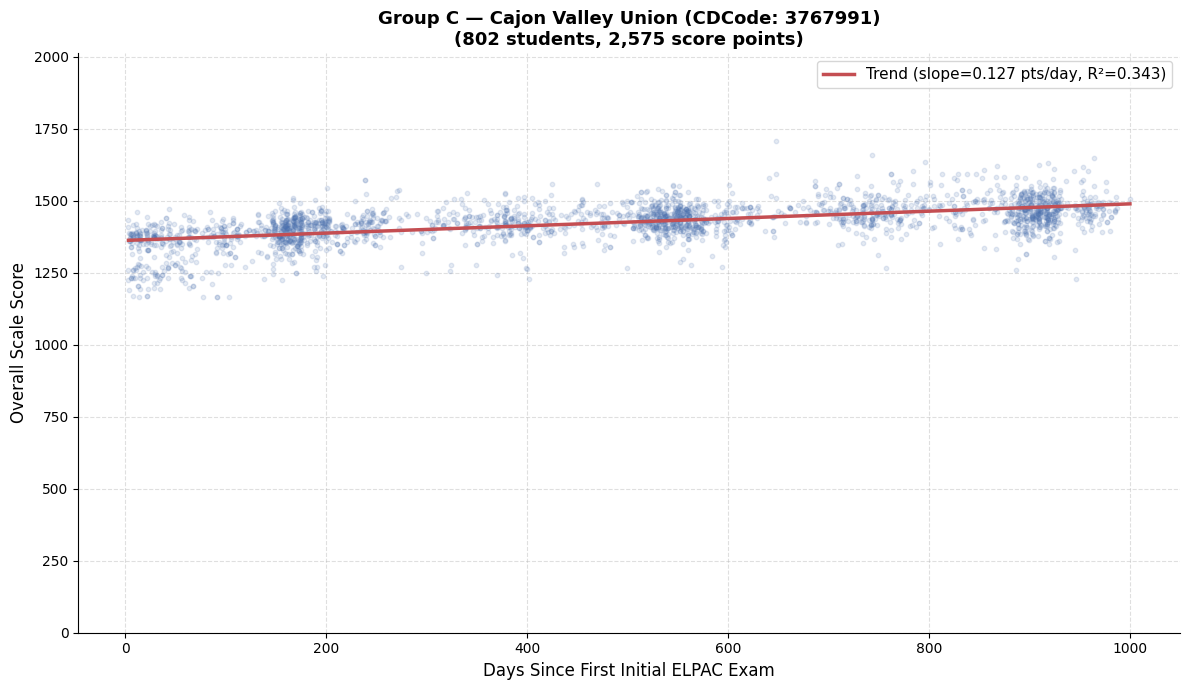

Saved: plots/group_c_district_3767991_Cajon_Valley_Union.png


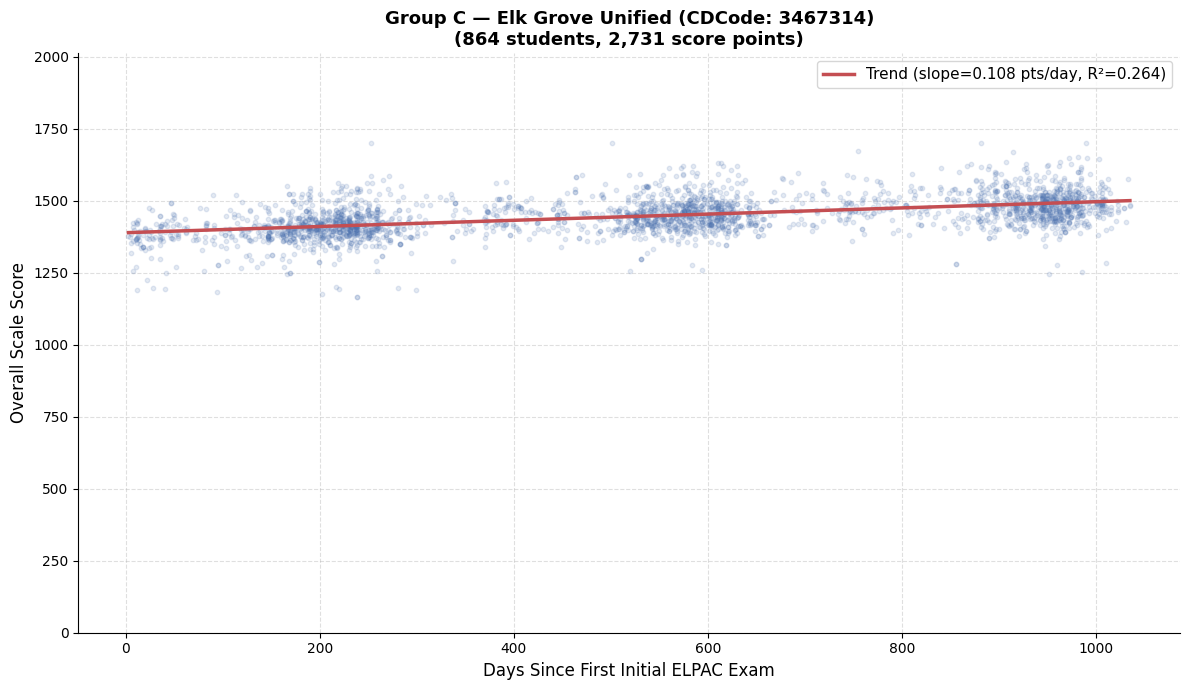

Saved: plots/group_c_district_3467314_Elk_Grove_Unified.png


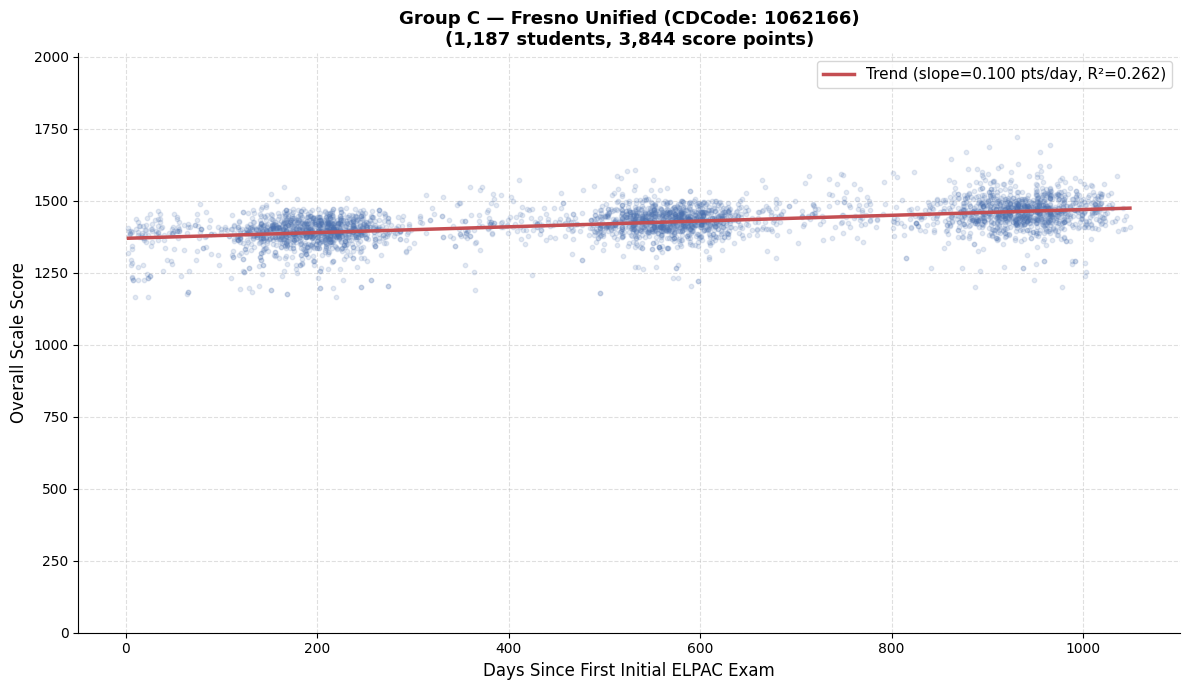

Saved: plots/group_c_district_1062166_Fresno_Unified.png


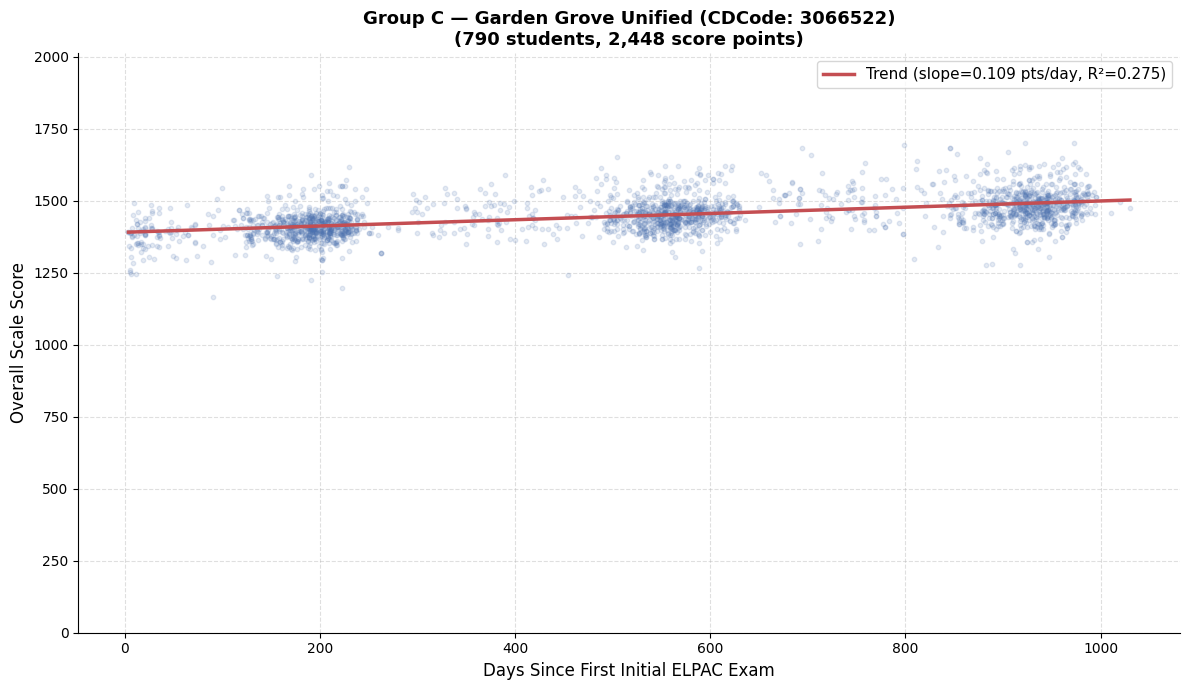

Saved: plots/group_c_district_3066522_Garden_Grove_Unified.png


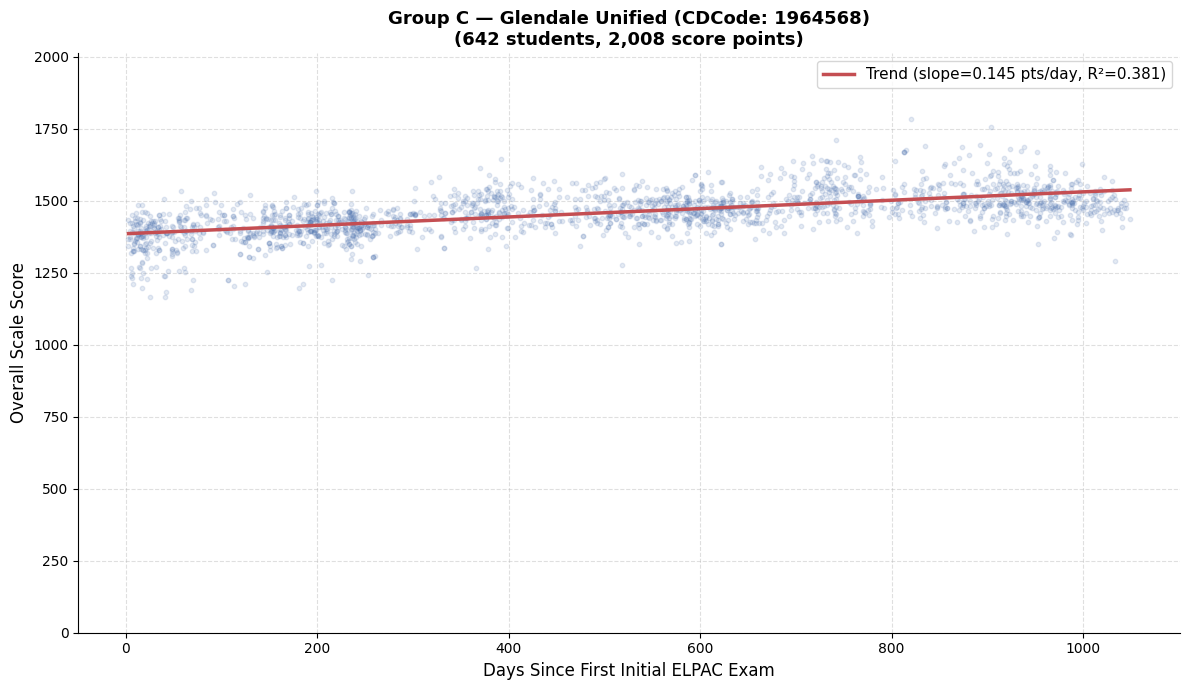

Saved: plots/group_c_district_1964568_Glendale_Unified.png


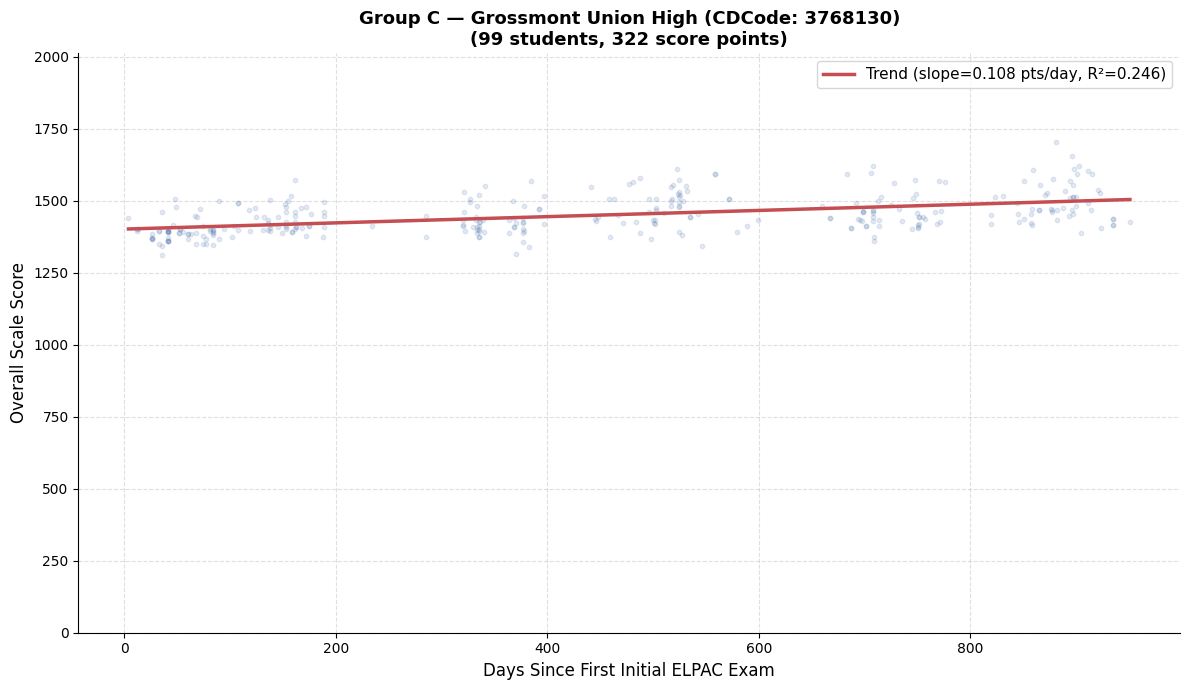

Saved: plots/group_c_district_3768130_Grossmont_Union_High.png


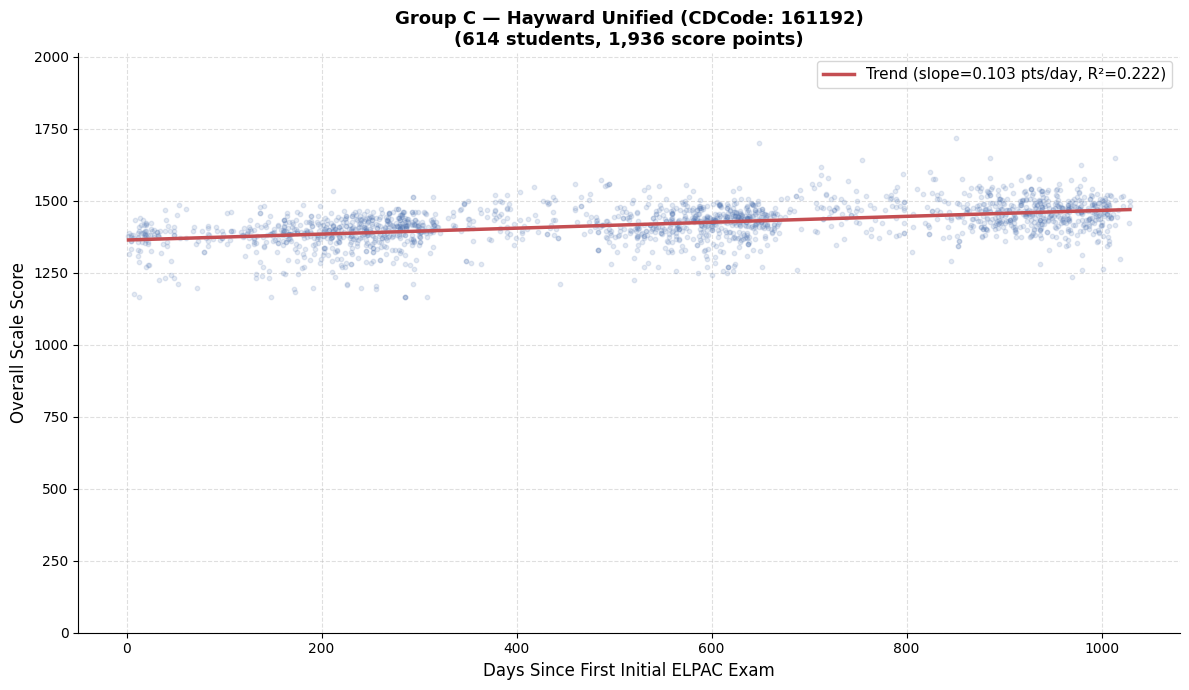

Saved: plots/group_c_district_161192_Hayward_Unified.png


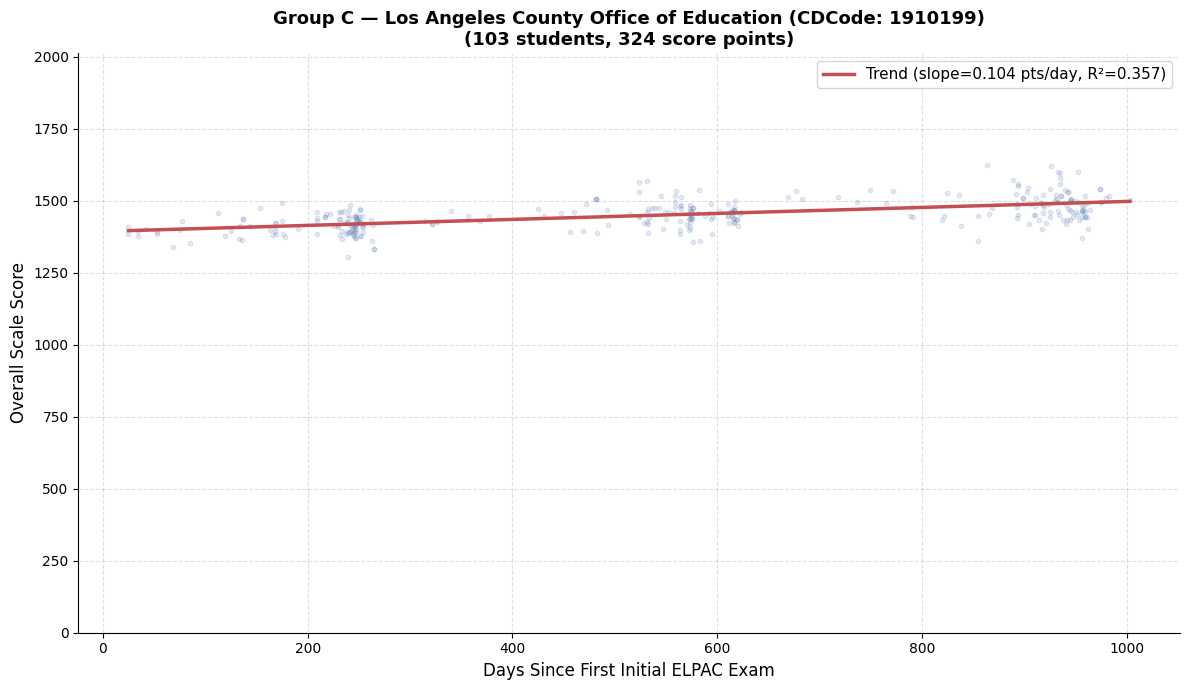

Saved: plots/group_c_district_1910199_Los_Angeles_County_Office_of_Education.png


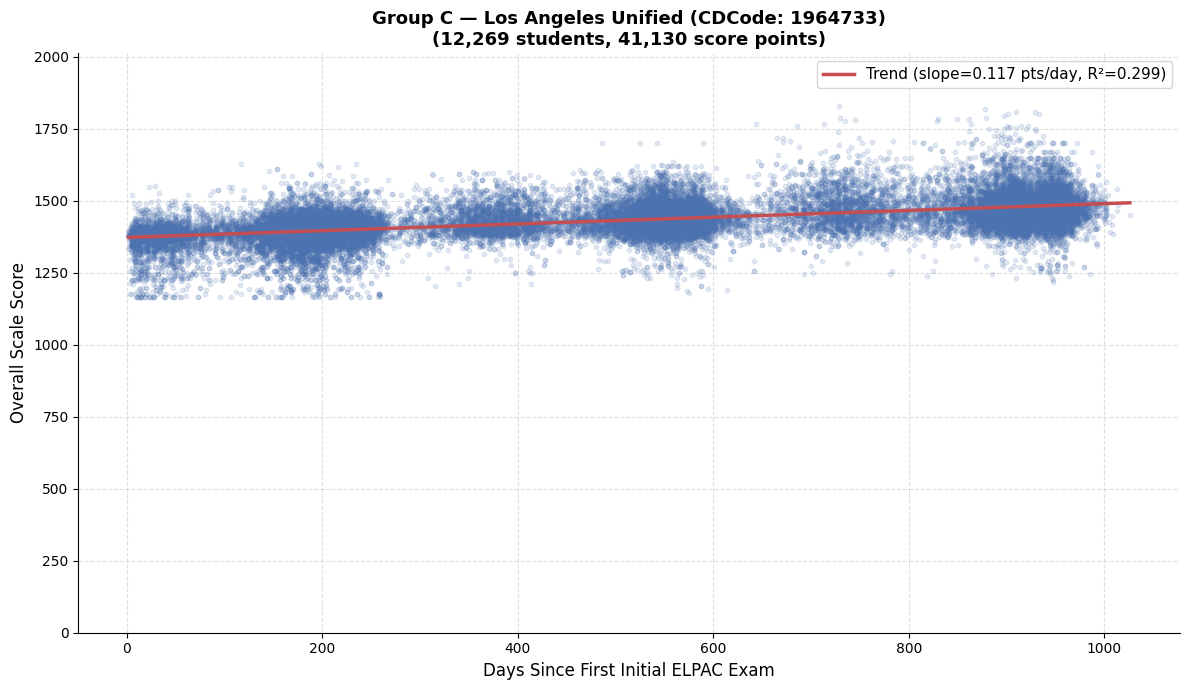

Saved: plots/group_c_district_1964733_Los_Angeles_Unified.png


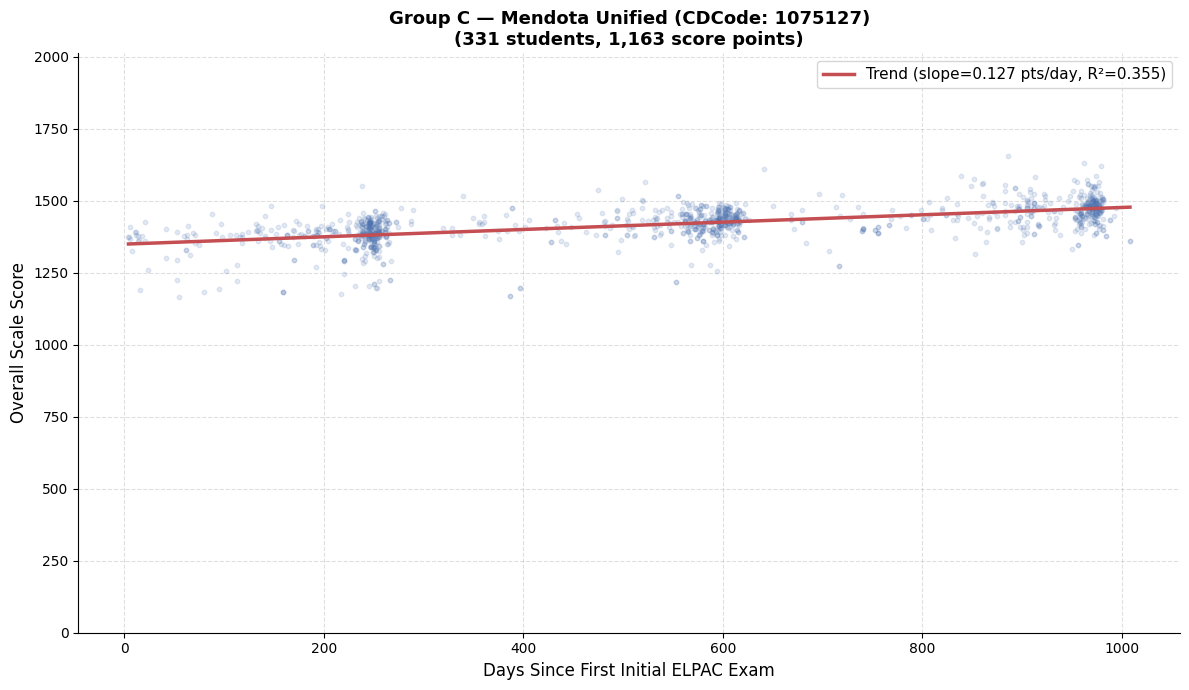

Saved: plots/group_c_district_1075127_Mendota_Unified.png


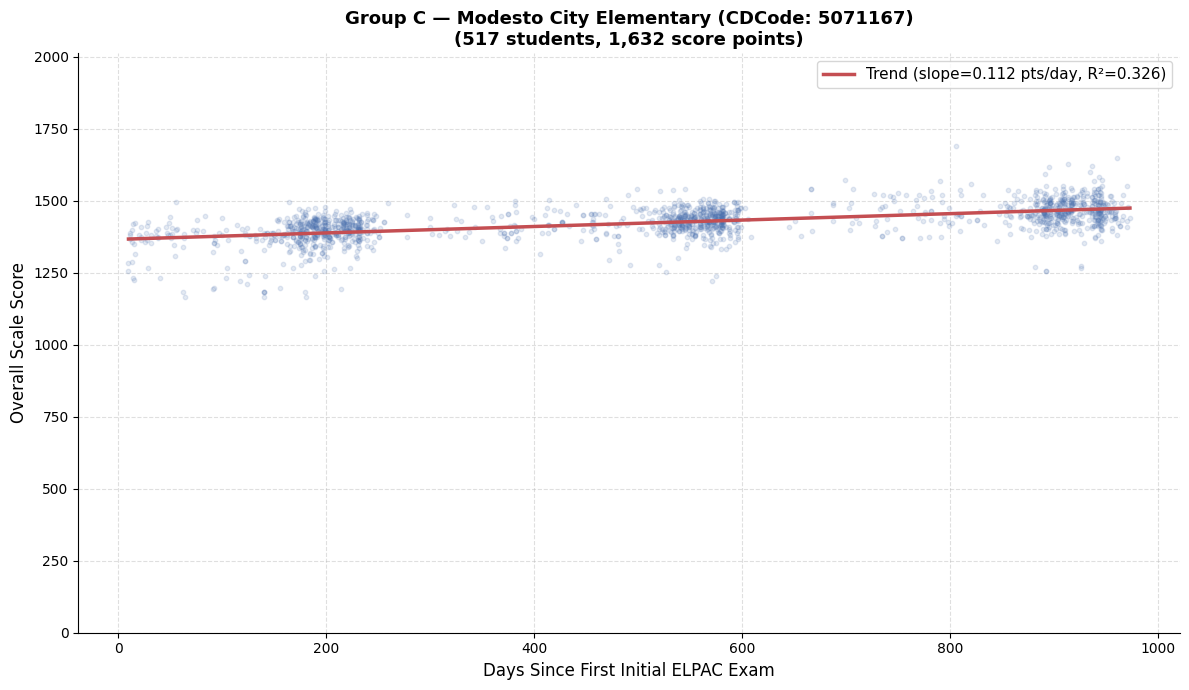

Saved: plots/group_c_district_5071167_Modesto_City_Elementary.png


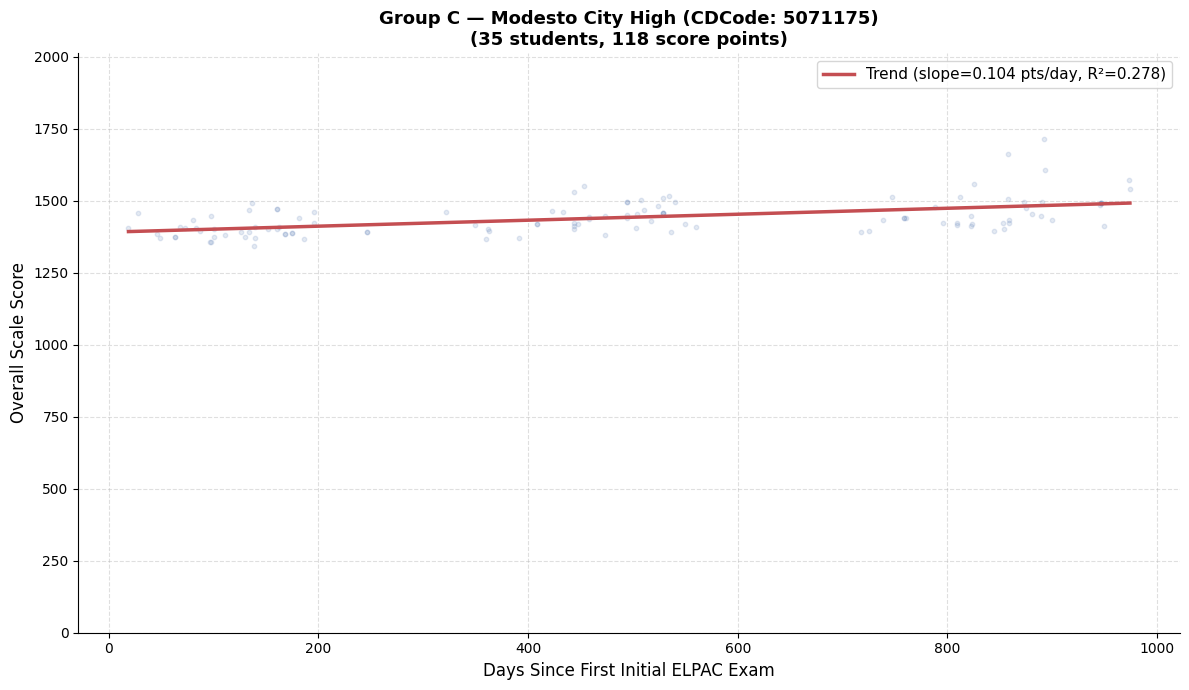

Saved: plots/group_c_district_5071175_Modesto_City_High.png


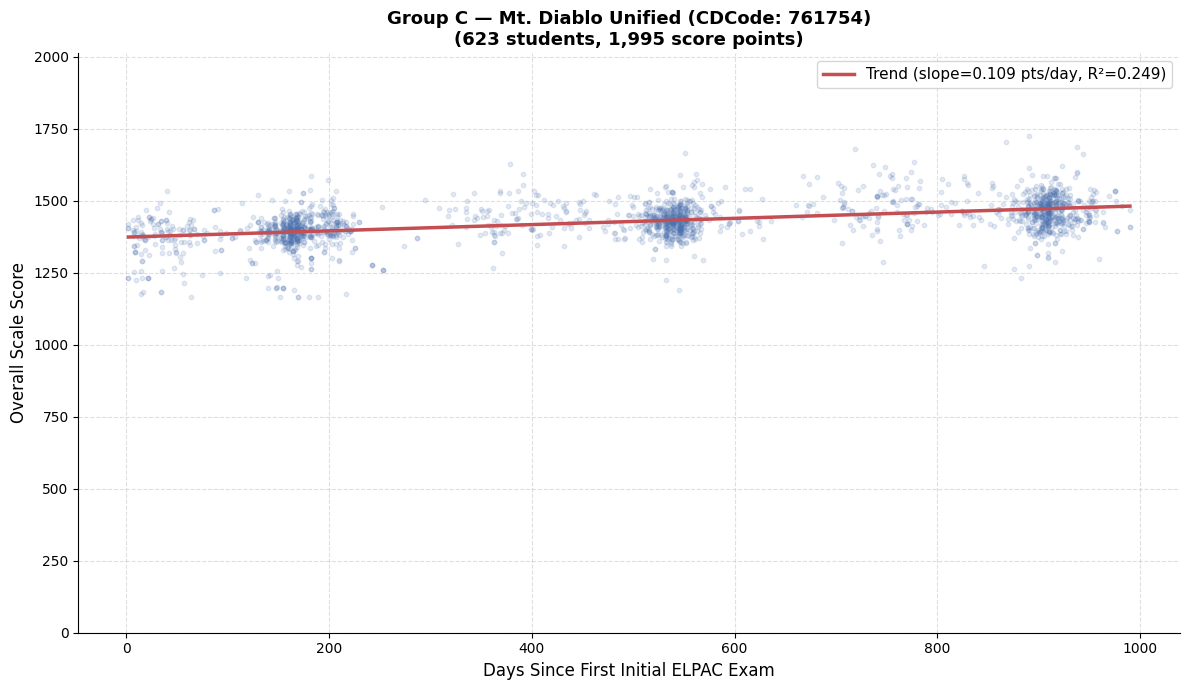

Saved: plots/group_c_district_761754_Mt._Diablo_Unified.png


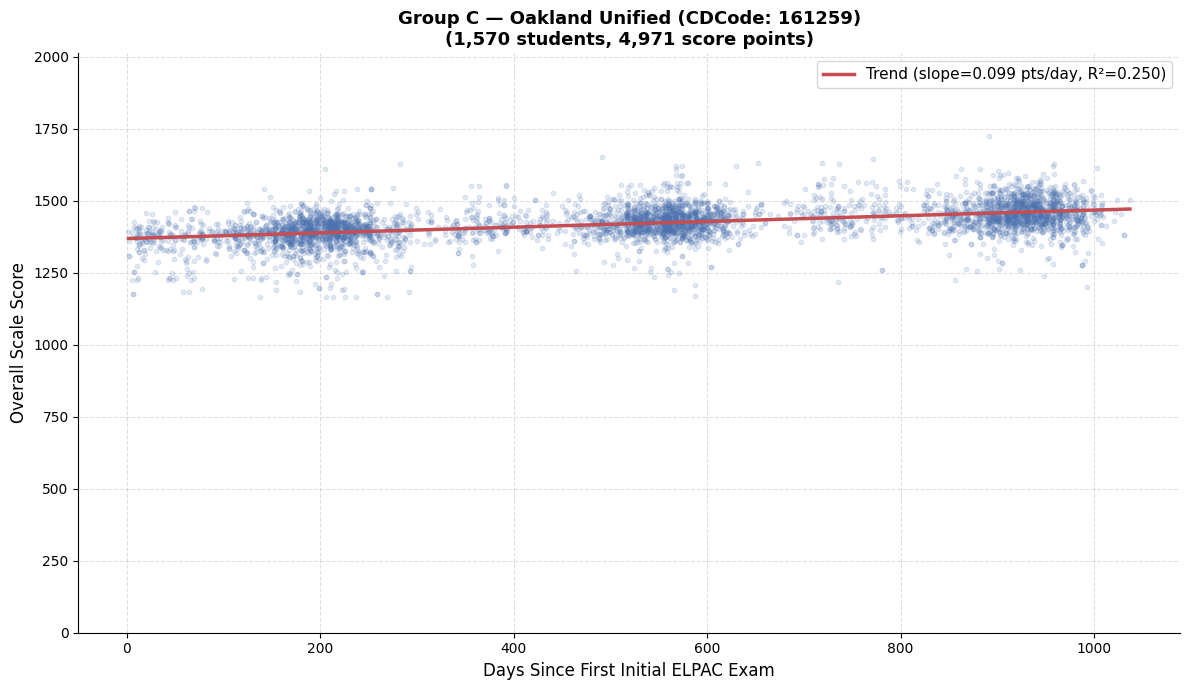

Saved: plots/group_c_district_161259_Oakland_Unified.png


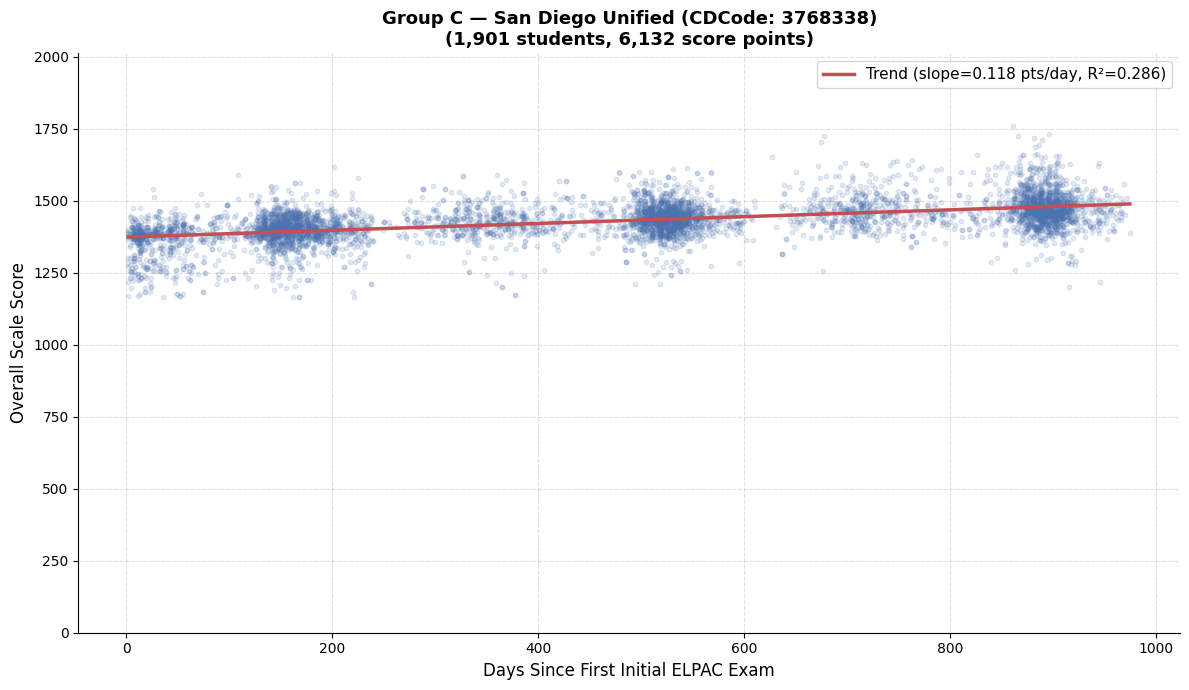

Saved: plots/group_c_district_3768338_San_Diego_Unified.png


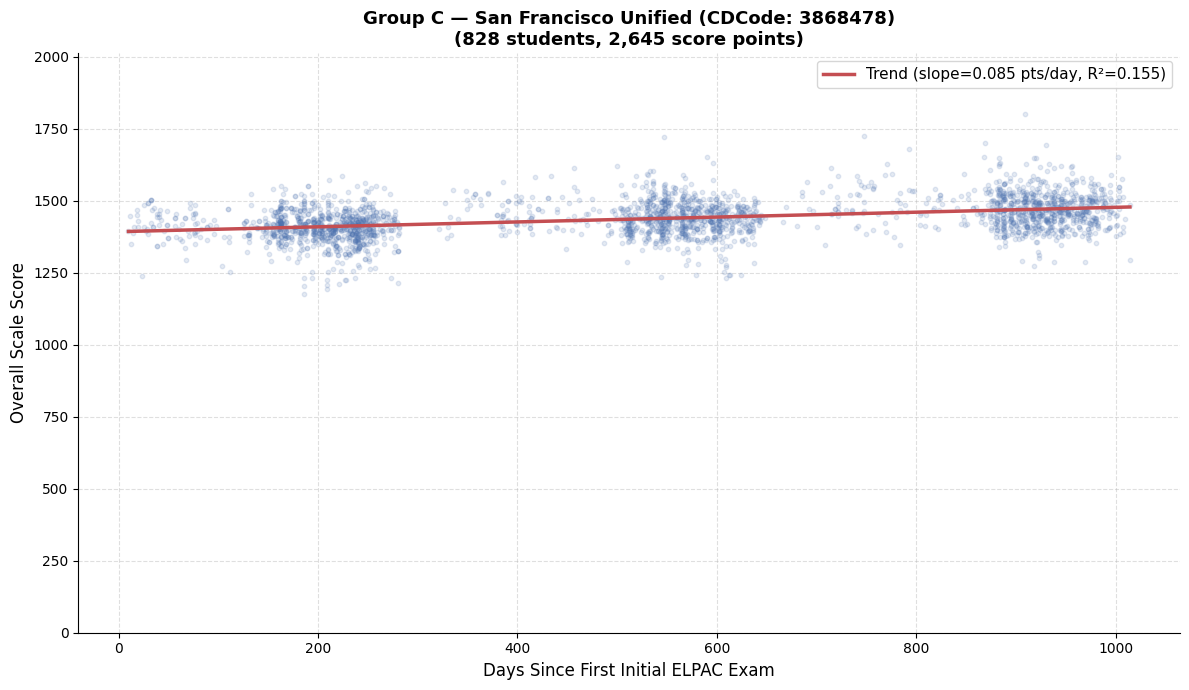

Saved: plots/group_c_district_3868478_San_Francisco_Unified.png


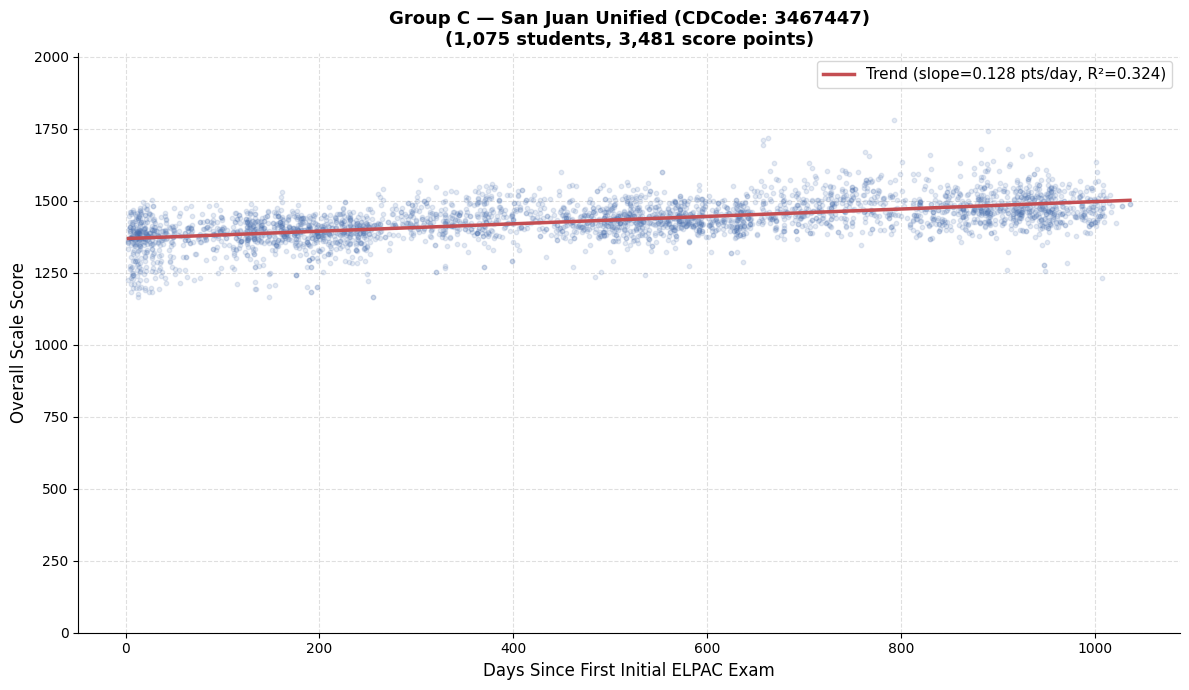

Saved: plots/group_c_district_3467447_San_Juan_Unified.png


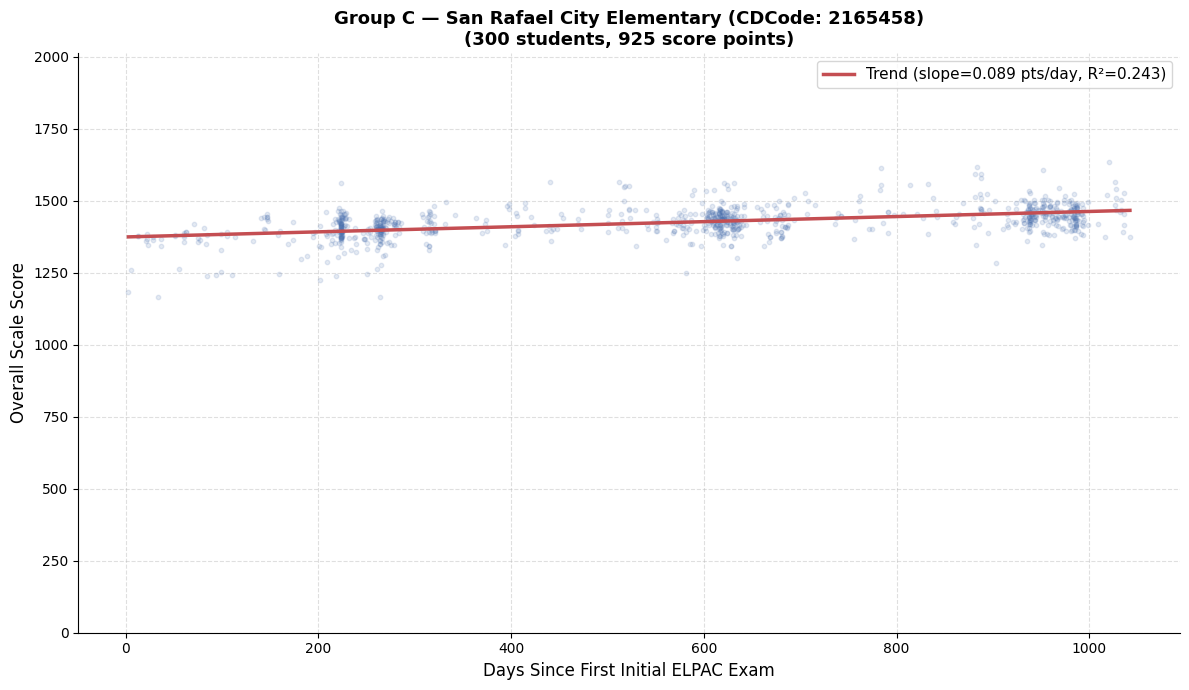

Saved: plots/group_c_district_2165458_San_Rafael_City_Elementary.png


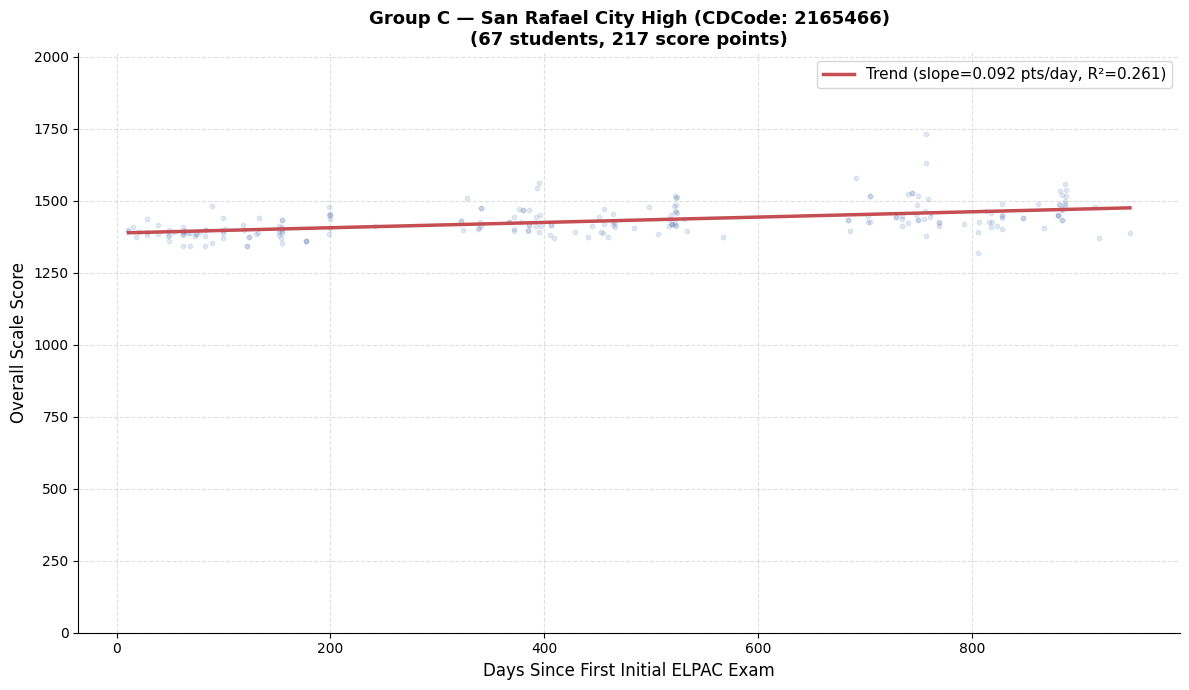

Saved: plots/group_c_district_2165466_San_Rafael_City_High.png


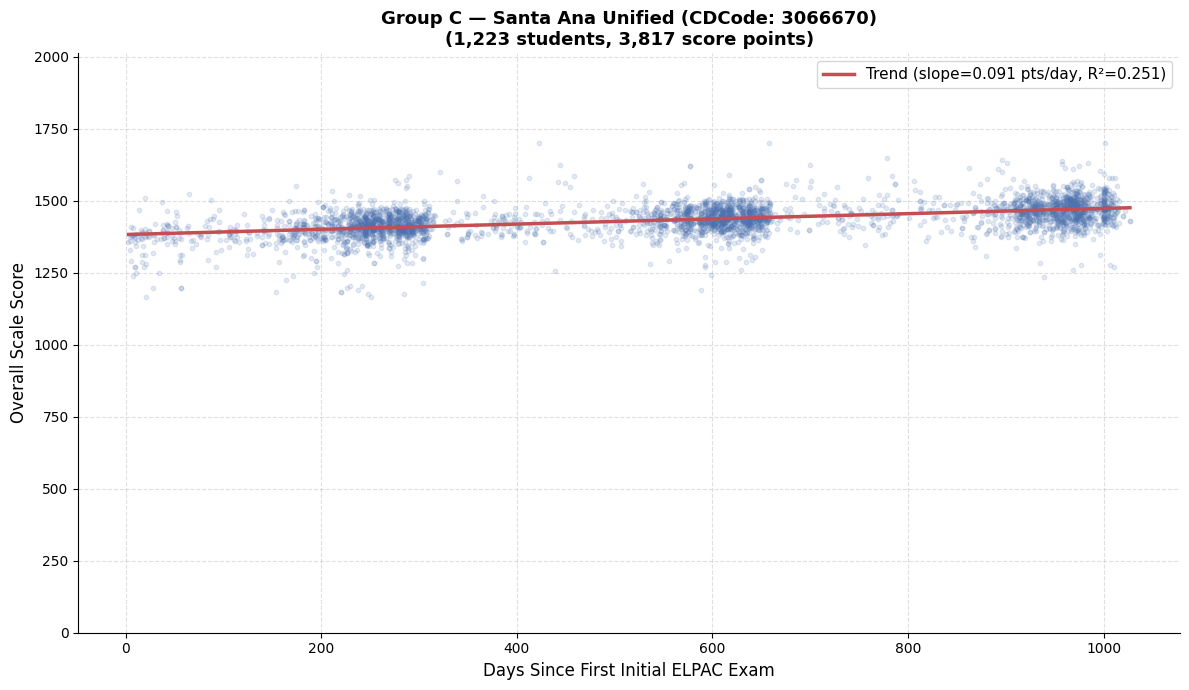

Saved: plots/group_c_district_3066670_Santa_Ana_Unified.png


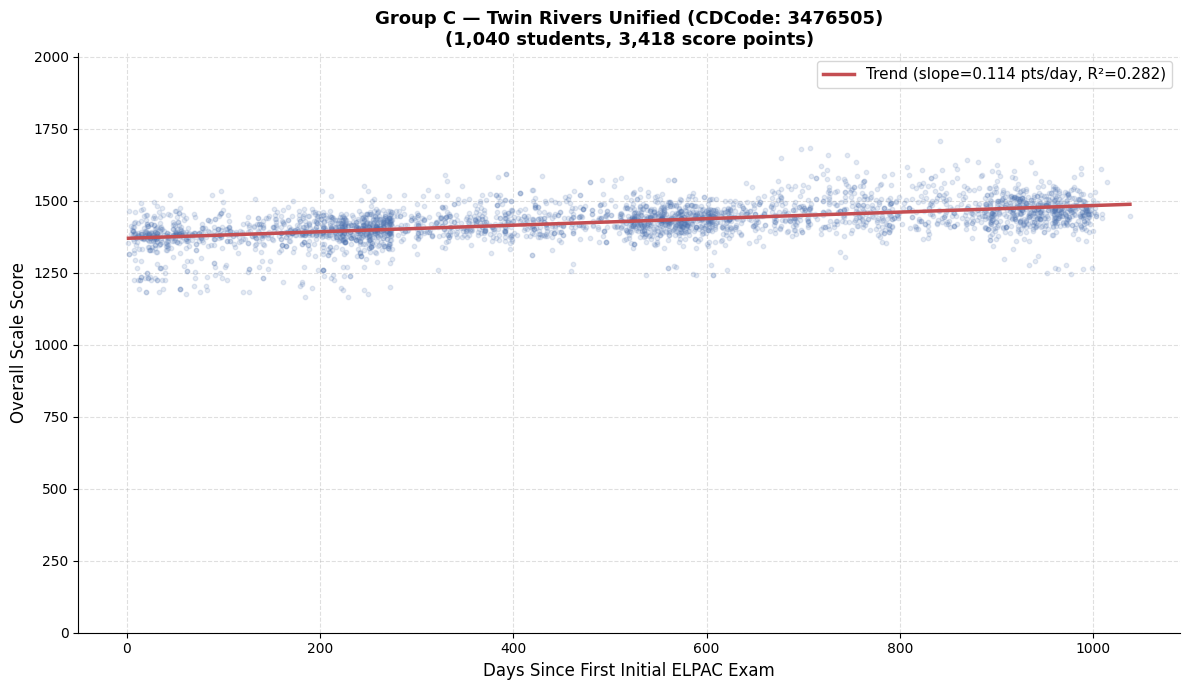

Saved: plots/group_c_district_3476505_Twin_Rivers_Unified.png


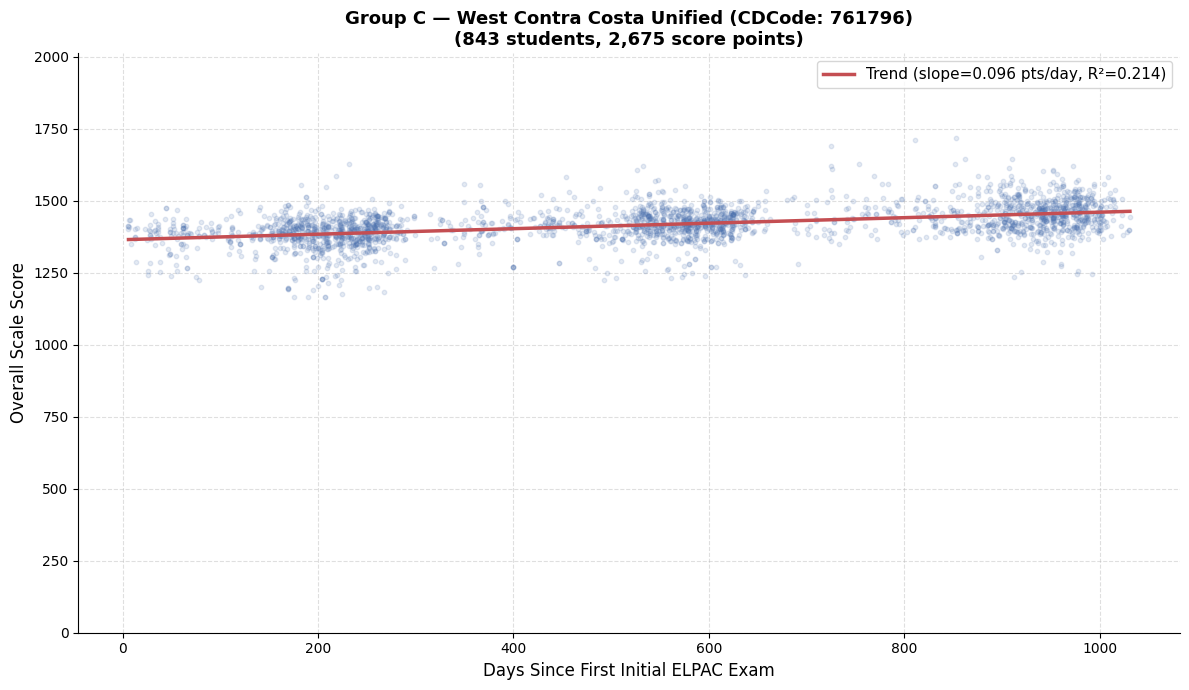

Saved: plots/group_c_district_761796_West_Contra_Costa_Unified.png


In [9]:
# --- One scatter plot per district ---
for _, district_row in districts.iterrows():
    cd_code = district_row["CDCode"]
    dist_name = district_row["Districtname"]

    dist_data = scatter_df[scatter_df["CDCode"] == cd_code]
    x = dist_data["days"].values
    y = dist_data["score"].values

    if len(x) < 2:
        print(f"Skipping {dist_name} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 300)
    trend_y = slope * trend_x + intercept
    r_squared = r_value ** 2
    ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"Group C — {dist_name} (CDCode: {cd_code})\n"
                 f"({dist_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = str(dist_name).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/group_c_district_{cd_code}_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/group_c_district_{cd_code}_{safe_name}.png")

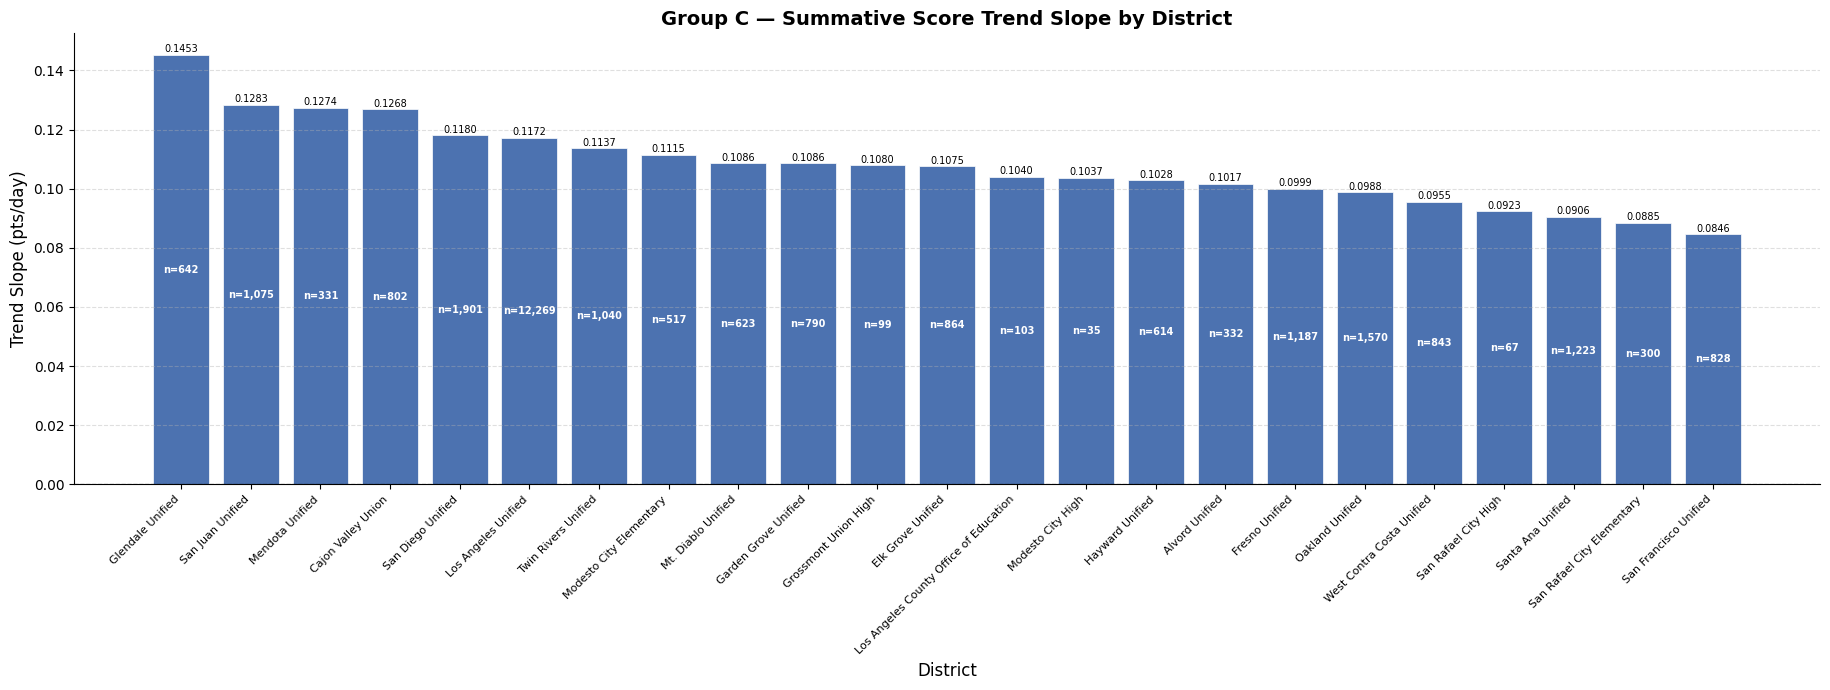

Saved: plots/group_c_slope_by_district.png


In [10]:
# --- Compute slope and student count per district ---
district_slopes = {}
district_counts = {}

for _, district_row in districts.iterrows():
    cd_code = district_row["CDCode"]
    dist_name = district_row["Districtname"]

    dist_data = scatter_df[scatter_df["CDCode"] == cd_code]
    x = dist_data["days"].values
    y = dist_data["score"].values

    if len(x) < 2:
        continue

    slope, _, _, _, _ = stats.linregress(x, y)
    district_slopes[dist_name] = slope
    district_counts[dist_name] = dist_data["SSID"].nunique()

# Sort by slope descending
sorted_districts = sorted(district_slopes.items(), key=lambda x: -x[1])
dist_names = [d[0] for d in sorted_districts]
slopes = [d[1] for d in sorted_districts]
counts = [district_counts[d] for d in dist_names]

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(max(14, len(dist_names) * 0.8), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(dist_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label on top/bottom of each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(dist_names)))
ax.set_xticklabels(dist_names, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("District", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title("Group C — Summative Score Trend Slope by District", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("plots/group_c_slope_by_district.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: plots/group_c_slope_by_district.png")